In [1]:
%load_ext autoreload
%autoreload 2

In [21]:
import sys

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
import regionmask
import seaborn as sns
import xarray as xr

from src.conversion_energy.pv import (
    DEFAULT_PV_CONFIGURATION,
    NORMALISED_ROOFTOP_PV_CONFIGURATION,
    ROOFTOP_PV_CONFIGURATION,
    compute_pv_for_grid,
    compute_pv_for_pixel,
    compute_pv_for_pixel_all_timesteps,
)
from src.data_processing.load_data import ClimateModelData, ClimateReanalysisData
from src.utils.utils_xarray import (
    get_time_resolution,
    match_instaneous_to_mean_values,
    match_time_steps,
    match_time_steps_interpolate,
    sel_extent,
)

sns.set_style("whitegrid", {"grid.color": ".93"})

In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"

path_energy_ch = path_data_processed / "energy" / "ch"

path_figs = Path(paths["path_figs"])

# Load data

In [4]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

institute = climate_model_chain.split("-")[0]
rcm = climate_model_chain.split("_")[0]
gcm = climate_model_chain.split("_")[1]
ensemble = climate_model_chain.split("_")[-1]

In [5]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}
extent_ch = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}

In [15]:
ds_rsds_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "bias_corrected"
    / "3hr"
    / "rsds.zarr",
    extent=extent_ch,
)

ds_tas_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "bias_corrected"
    / "3hr"
    / "tas.zarr",
    extent=extent_ch,
)

ds_sfcWind_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "bias_corrected"
    / "3hr"
    / "sfcWind.zarr",
    extent=extent_ch,
)

## Match instantaneous values

In [ ]:
time_range = pd.date_range(
    start=ds_tas_bc.ds_data.time.values[0],
    end=ds_tas_bc.ds_data.time.values[-1],
    freq="1h",
)

time_range = time_range[~((time_range.month == 2) & (time_range.day == 29))]

data_hourly = ds_tas_bc.ds_data.interp(time=time_range)
ds_data = data_hourly.resample(time="3h", label="left", closed="left").mean()

ds_data = ds_data.sel(
    time=~((ds_data["time.month"] == 2) & (ds_data["time.day"] == 29))
)

In [22]:
ds_data["time"] = ds_data.time + pd.Timedelta(hours=1, minutes=30)

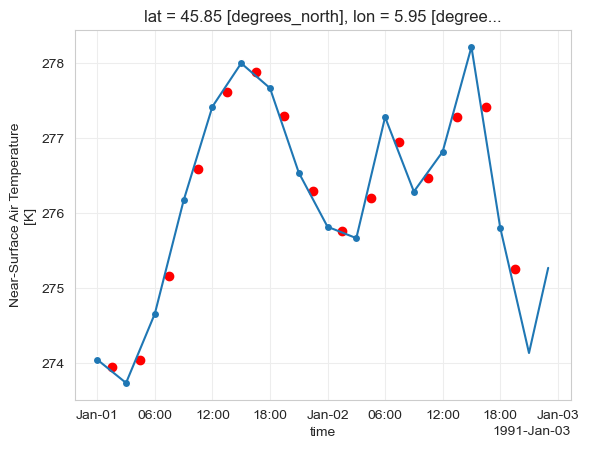

In [ ]:
data_hourly.isel(time=slice(0, 48), lat=0, lon=0).tas.plot()
ds_data.isel(time=slice(0, 15), lat=0, lon=0).tas.plot.scatter(
    x="time", y="tas", color="red"
)
ds_tas_bc.ds_data.isel(time=slice(0, 15), lat=0, lon=0).tas.plot.scatter(
    x="time", y="tas"
)

In [8]:
ds_rsds_bc_subset = ds_rsds_bc.ds_data.load()
ds_tas_bc_subset = ds_tas_bc.ds_data.load()
ds_sfcWind_bc_subset = ds_sfcWind_bc.ds_data.load()

In [9]:
regridded_cordex_path = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)


ds_orog = xr.open_dataset(sorted((regridded_cordex_path / "fx").glob("*.nc"))[0]).sel(
    lat=slice(extent_ch["lat_min"], extent_ch["lat_max"]),
    lon=slice(extent_ch["lon_min"], extent_ch["lon_max"]),
)

# Compute PV output for one location

In [ ]:
idx = 404
time = ds_rsds_bc_subset.time.values[idx]
lat = ds_rsds_bc_subset.lat.values[10]
lon = ds_rsds_bc_subset.lon.values[10]


results = compute_pv_for_pixel(
    ds_rsds_bc_subset.time.values[idx],
    ds_rsds_bc_subset.lat.values[0],
    ds_rsds_bc_subset.lon.values[0],
    ds_rsds_bc_subset.sel(time=time, lat=lat, lon=lon).rsds.values,
    ds_tas_bc_subset.sel(time=time, lat=lat, lon=lon).tas.values - 273.15,
    ds_sfcWind_bc_subset.sel(time=time, lat=lat, lon=lon).sfcWind.values,
    tilt=30,
    azimuth=180,
    pv_configuration=NORMALISED_ROOFTOP_PV_CONFIGURATION,
    system_loss=0.14,
)

results

array([196.43097604])

# Scale the PV computation

## Scale locations

In [ ]:
# Subset data (only a small grid for testing)
da_rsds = ds_rsds_bc_subset.rsds.isel(lat=slice(0, 2), lon=slice(0, 2))
da_tas = (ds_tas_bc_subset.tas - 273.15).isel(lat=slice(0, 2), lon=slice(0, 2))
da_sfcWind = ds_sfcWind_bc_subset.sfcWind.isel(lat=slice(0, 2), lon=slice(0, 2))
da_orog = ds_orog.orog.isel(lat=slice(0, 2), lon=slice(0, 2))

In [ ]:
da_pv_loc = compute_pv_for_pixel_all_timesteps(
    da_rsds, da_tas, da_sfcWind, lat=da_tas.lat.values[0], lon=da_tas.lon.values[0]
)

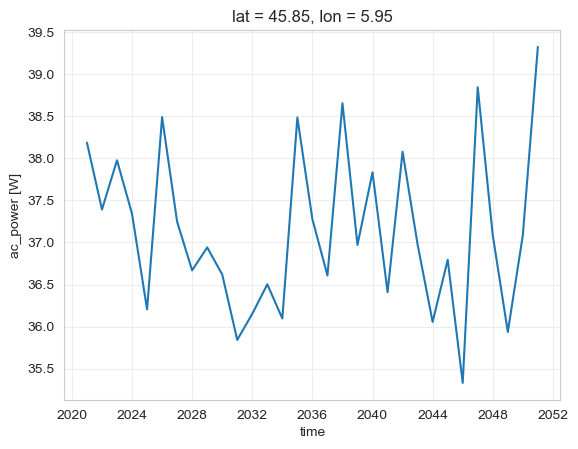

In [ ]:
da_pv_loc_yearly_mean = da_pv_loc.resample(time="YE").mean()
da_pv_loc_yearly_mean.plot()

In [ ]:
da_rsds = ds_rsds_bc_subset.rsds
da_tas = ds_tas_bc_subset.tas - 273.15
da_sfcWind = ds_sfcWind_bc_subset.sfcWind

## Naive (for loop)

In [ ]:
list_da_pv = []

for lat in da_rsds.lat.values:
    for lon in da_rsds.lon.values:
        list_da_pv.append(
            compute_pv_for_pixel_all_timesteps(
                da_rsds, da_tas, da_sfcWind, lat=lat, lon=lon
            )
        )

da_pv_ch = xr.combine_by_coords(list_da_pv)

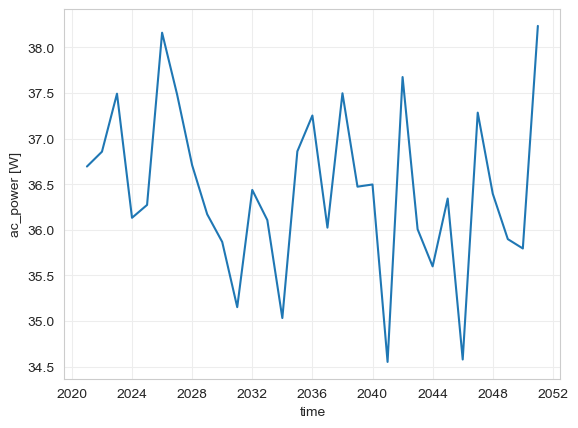

In [ ]:
da_pv_ch_yearly_mean = da_pv_ch.resample(time="YE").mean(["time", "lat", "lon"])
da_pv_ch_yearly_mean.ac_power.plot()
plt.show()

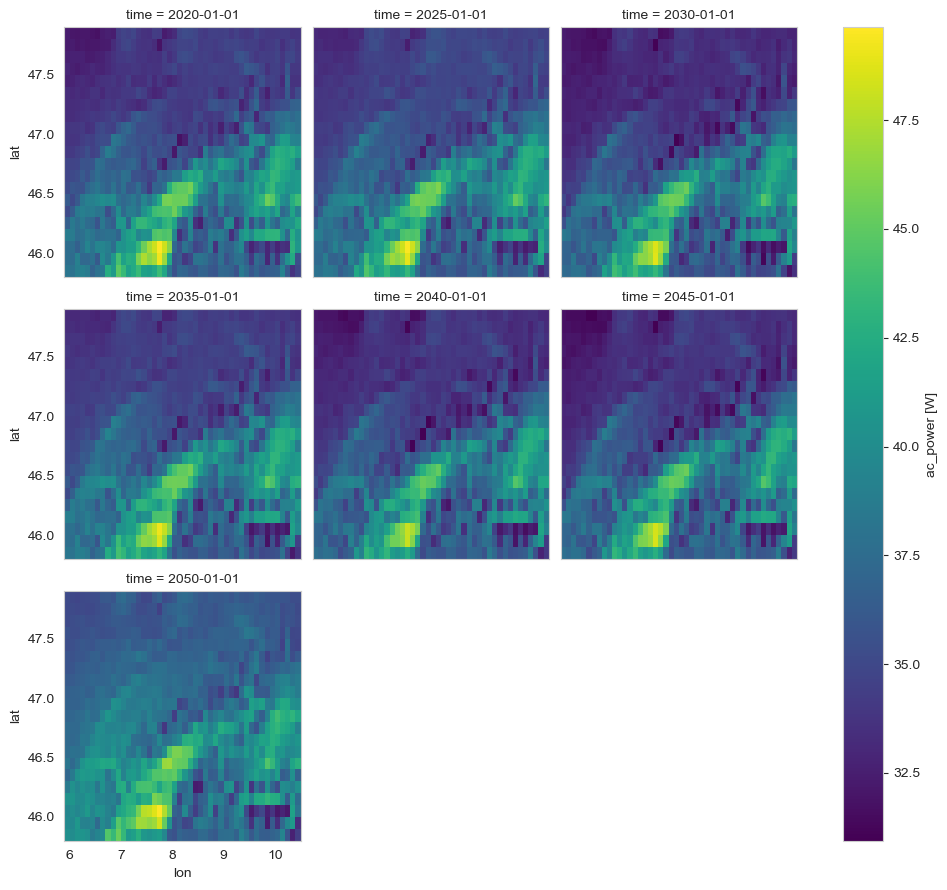

In [ ]:
da_pv_ch_yearly_per_loc_mean = da_pv_ch.resample(time="YE").mean(["time"])
da_pv_ch_5year_mean = da_pv_ch.resample(time="5YS").mean()
da_pv_ch_5year_mean.ac_power.plot(col="time", col_wrap=3)
plt.show()

## Multiprocessing

In [27]:
da_rsds = ds_rsds_bc_subset.rsds.sel(time=slice("2020", "2021"))
da_tas = ds_tas_bc_subset.tas.sel(time=slice("2020", "2021")) - 273.15
da_sfcWind = ds_sfcWind_bc_subset.sfcWind.sel(time=slice("2020", "2021"))

da_pv_ch = compute_pv_for_grid(
    da_rsds,
    da_tas,
    da_sfcWind,
    tilt=30,
    azimuth=180,
    pv_configuration=DEFAULT_PV_CONFIGURATION,
    num_workers=10,
)

In [85]:
da_pv_ch.to_netcdf("pv_ch_sample.nc")

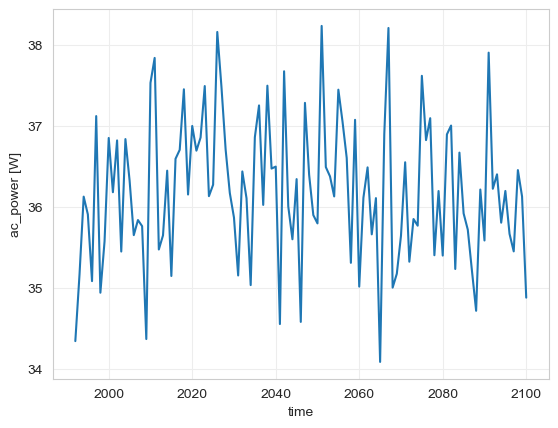

In [ ]:
da_pv_ch_yearly_mean = da_pv_ch.resample(time="YE").mean(["time", "lat", "lon"])
da_pv_ch_yearly_mean.ac_power.plot()
plt.show()

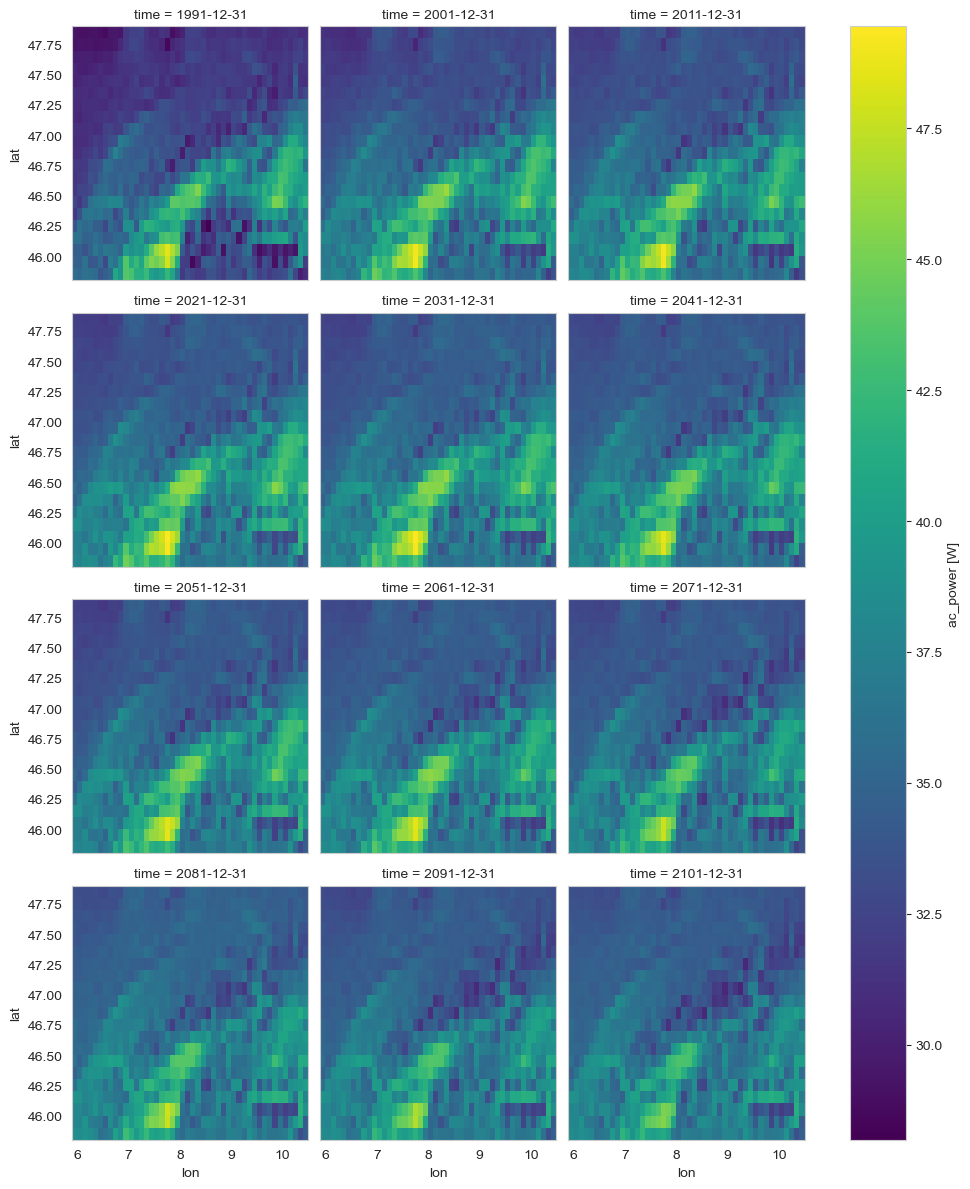

In [ ]:
da_pv_ch_decadal_mean = da_pv_ch.resample(time="10YE").mean()
da_pv_ch_decadal_mean.ac_power.plot(col="time", col_wrap=3)
plt.show()

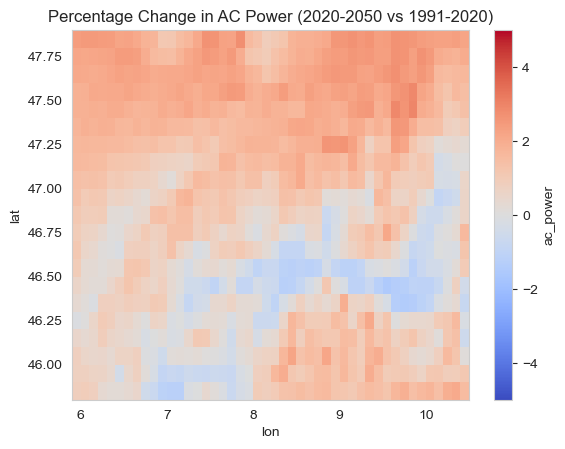

In [ ]:
# Define the periods
period1 = slice("1991-01-01", "2020-12-31")
period2 = slice("2020-01-01", "2050-12-31")

# Calculate the mean AC power for each period
mean_ac_power_period1 = da_pv_ch.sel(time=period1).mean(dim="time")
mean_ac_power_period2 = da_pv_ch.sel(time=period2).mean(dim="time")

# Compute the percentage change
percentage_change = (
    (mean_ac_power_period2 - mean_ac_power_period1) / mean_ac_power_period1
) * 100

# Plot the percentage change as a map
percentage_change.ac_power.plot(cmap="coolwarm", robust=True, vmin=-5, vmax=5)
plt.title("Percentage Change in AC Power (2020-2050 vs 1991-2020)")
plt.show()

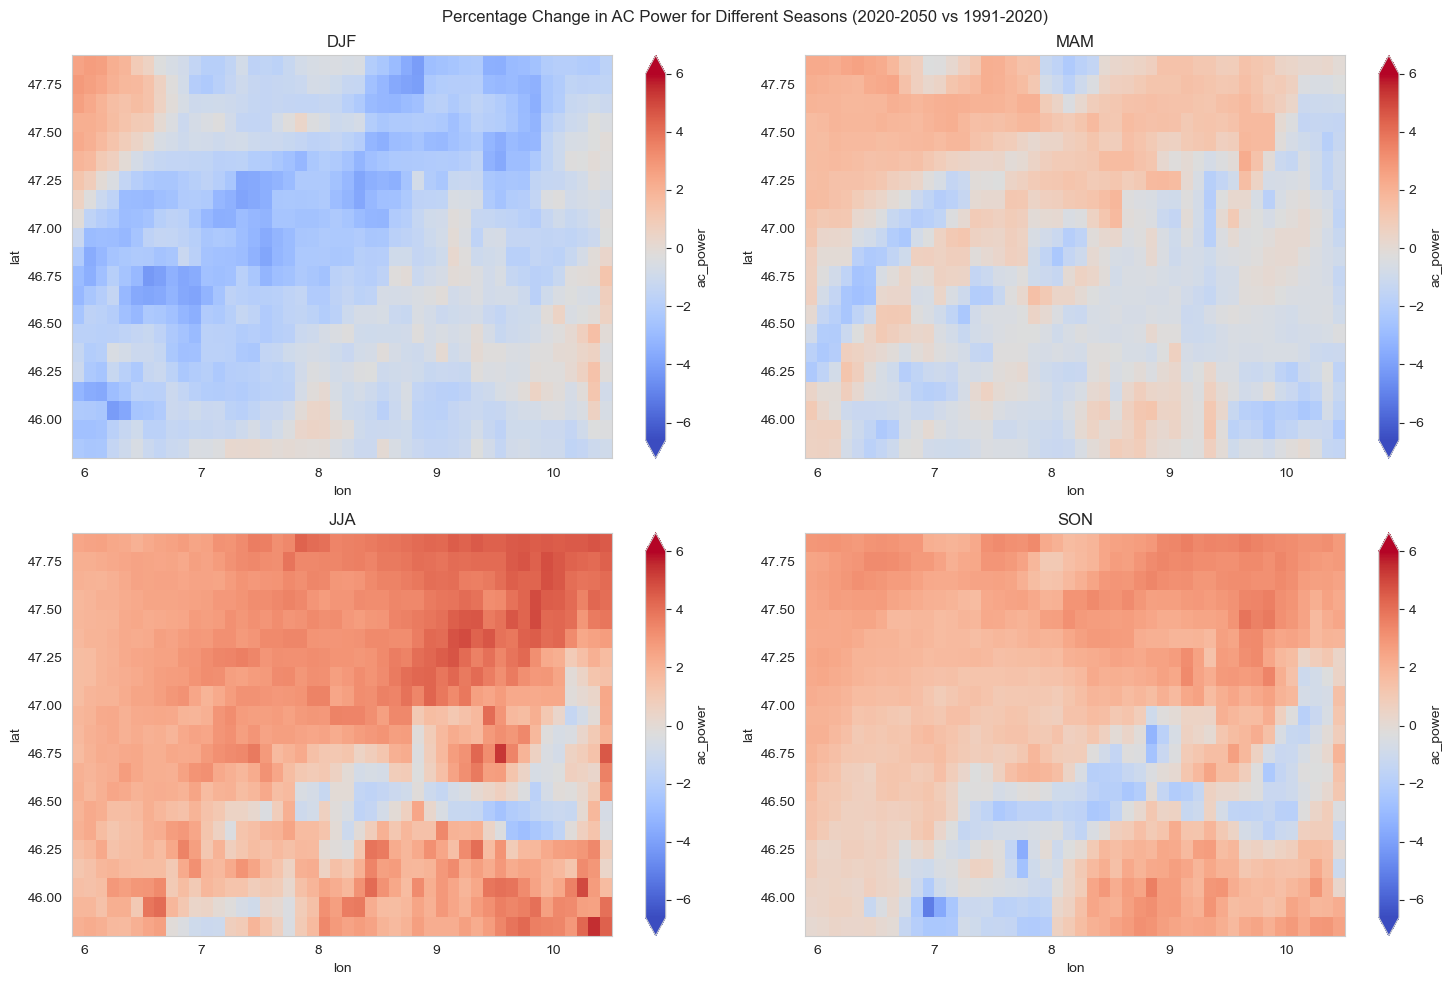

In [ ]:
# Define the seasons
seasons = {"DJF": (12, 1, 2), "MAM": (3, 4, 5), "JJA": (6, 7, 8), "SON": (9, 10, 11)}


# Function to compute seasonal mean
def compute_seasonal_mean(da, season_months):
    return (
        da.sel(time=da["time.month"].isin(season_months)).resample(time="QS-DEC").mean()
    )


# Compute seasonal means for each period
seasonal_means_period1 = {
    season: compute_seasonal_mean(da_pv_ch.sel(time=period1), months)
    for season, months in seasons.items()
}
seasonal_means_period2 = {
    season: compute_seasonal_mean(da_pv_ch.sel(time=period2), months)
    for season, months in seasons.items()
}

# Compute the mean for each season over the entire period
mean_seasonal_means_period1 = {
    season: da.mean(dim="time") for season, da in seasonal_means_period1.items()
}
mean_seasonal_means_period2 = {
    season: da.mean(dim="time") for season, da in seasonal_means_period2.items()
}

# Compute the percentage change for each season
percentage_change_seasonal = {
    season: (
        (mean_seasonal_means_period2[season] - mean_seasonal_means_period1[season])
        / mean_seasonal_means_period1[season]
    )
    * 100
    for season in seasons.keys()
}

# Plot the percentage change for each season in a single figure with subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))

max_value = max(
    [da.ac_power.max().values for da in percentage_change_seasonal.values()]
)
min_value = min(
    [da.ac_power.min().values for da in percentage_change_seasonal.values()]
)

for ax, (season, da) in zip(axes.flatten(), percentage_change_seasonal.items()):
    da.ac_power.plot(
        ax=ax,
        cmap="coolwarm",
        robust=True,
        vmin=int(max_value) + 1,
        vmax=-int(max_value) - 1,
    )
    ax.set_title(f"{season}")

fig.suptitle(
    "Percentage Change in AC Power for Different Seasons (2020-2050 vs 1991-2020)"
)
plt.tight_layout()
plt.show()

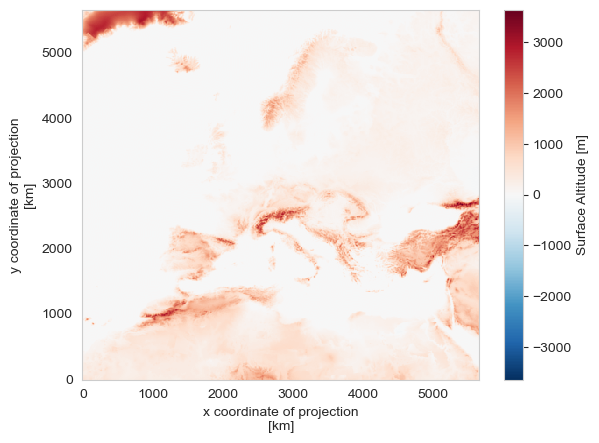

In [ ]:
xr.open_dataset(
    "/net/atmos/data/cordex/EUR-11/historical/fx/orog/CNRM/CNRM-CERFACS-CNRM-CM5/CNRM-ALADIN63/r1i1p1/orog_EUR-11_CNRM-CERFACS-CNRM-CM5_historical_r1i1p1_CNRM-ALADIN63_v2_fx.nc"
).orog.plot()

# Aggregate data

## Test

In [19]:
gdf_voronoi_nexuse_nodes = gpd.read_file(
    path_energy_ch / "gis_nexuse" / "Voronoi_2050_revised_clipped.shp"
)

In [ ]:
gdf_voronoi_nexuse_nodes_latlon = gdf_voronoi_nexuse_nodes.to_crs("EPSG:4326")
buffered_voronoi = gdf_voronoi_nexuse_nodes_latlon.copy()
buffered_voronoi["geometry"] = buffered_voronoi.geometry.apply(
    lambda geom: geom.buffer(0.04, cap_style=3, resolution=16)
)

In [ ]:
from shapely.geometry import Point

# Create a list of points from the lat/lon grid
points = [
    Point(lon, lat)
    for lat in ds_rsds_bc_subset.lat.values
    for lon in ds_rsds_bc_subset.lon.values
]

# Convert the list of points into a GeoSeries
gdf_climate_grid = (
    gpd.GeoSeries(points).to_frame(name="geometry").set_crs(crs="epsg:4326")
)
gdf_climate_grid["lat"] = [point.y for point in gdf_climate_grid.geometry]
gdf_climate_grid["lon"] = [point.x for point in gdf_climate_grid.geometry]

<Axes: >

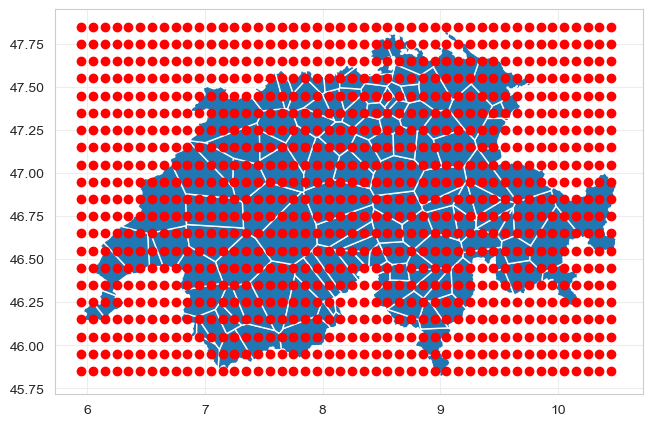

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
gdf_voronoi_nexuse_nodes_latlon.plot(ax=ax)
gdf_climate_grid.plot(ax=ax, color="red")

<Axes: >

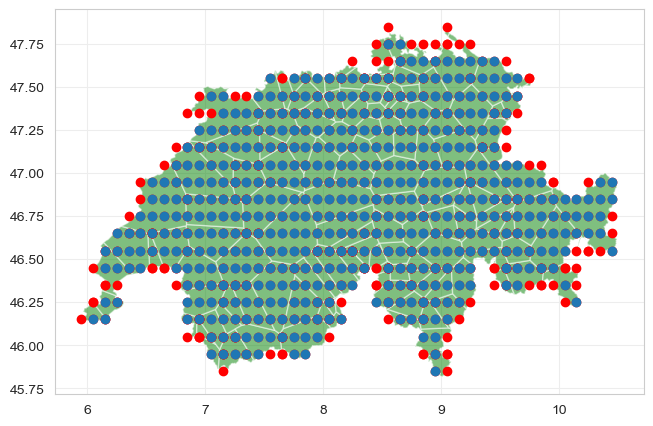

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
gdf_voronoi_nexuse_nodes_latlon.plot(ax=ax, color="green", alpha=0.5)
gpd.sjoin(
    gdf_climate_grid, buffered_voronoi, how="left", predicate="intersects"
).dropna().plot(ax=ax, color="red")
gpd.sjoin(
    gdf_climate_grid,
    gdf_voronoi_nexuse_nodes_latlon,
    how="left",
    predicate="intersects",
).dropna().plot(ax=ax)

In [ ]:
gdf_point_in_voronoi = gpd.sjoin(
    gdf_climate_grid, buffered_voronoi, how="left", predicate="intersects"
).dropna()
gdf_point_in_voronoi

,geometry,lat,lon,index_right,# idIntBus,BusName,SwissgridN,Country,SubRegion,ZoneId,...,Vmin,Vmax,StartYr,EndYr,DemandShar,WindShare,SolarShare,idDistProf,X_Coord,Y_Coord
12,POINT (7.15000 45.85000),45.85,7.15,1.0,26.0,CH_Fionnay_FFM_220,SFIONF2A,CH,VS,2.0,...,0.9,1.2,2015.0,2100.0,0.0011,0.0,0.0,66.0,590018.0,97892.6
30,POINT (8.95000 45.85000),45.85,8.95,0.0,153.0,CH_Mendrisio_150,SMENDR3A,CH,TI,2.0,...,0.9,1.2,2015.0,2100.0,0.0062,0.0,0.0,193.0,719083.0,80433.0
31,POINT (9.05000 45.85000),45.85,9.05,0.0,153.0,CH_Mendrisio_150,SMENDR3A,CH,TI,2.0,...,0.9,1.2,2015.0,2100.0,0.0062,0.0,0.0,193.0,719083.0,80433.0
57,POINT (7.05000 45.95000),45.95,7.05,2.0,12.0,CH_Vallorcine_220,SVALLO2A,CH,VS,2.0,...,0.9,1.2,2015.0,2100.0,0.0004,0.0,0.0,52.0,562196.0,100097.0
58,POINT (7.15000 45.95000),45.95,7.15,2.0,12.0,CH_Vallorcine_220,SVALLO2A,CH,VS,2.0,...,0.9,1.2,2015.0,2100.0,0.0004,0.0,0.0,52.0,562196.0,100097.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
905,POINT (9.05000 47.75000),47.75,9.05,133.0,92.0,CH_Schlattingen_220,SSCHLA2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0104,0.0,0.0,132.0,700492.0,279572.0
906,POINT (9.15000 47.75000),47.75,9.15,131.0,110.0,CH_Weinfelden_220,SWEINF2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0147,0.0,0.0,150.0,724495.0,269165.0
907,POINT (9.25000 47.75000),47.75,9.25,131.0,110.0,CH_Weinfelden_220,SWEINF2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0147,0.0,0.0,150.0,724495.0,269165.0
946,POINT (8.55000 47.85000),47.85,8.55,133.0,92.0,CH_Schlattingen_220,SSCHLA2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0104,0.0,0.0,132.0,700492.0,279572.0


In [25]:
len(np.unique(gdf_point_in_voronoi["# idIntBus"]))

135

In [ ]:
from shapely.geometry import Point


# Function to find the closest polygon for a point
def find_closest_polygon(point, polygons):
    # Calculate the distance from the point to the centroid of each polygon
    distances = [
        (polygon["# idIntBus"], point.distance(polygon.geometry.centroid))
        for _, polygon in polygons.iterrows()
    ]
    # Return the polygon with the smallest distance
    return min(distances, key=lambda x: x[1])[0]


# Example usage
# Assuming `buffered_voronoi` is a GeoDataFrame containing the polygons
# and `gdf_climate_grid` is a GeoDataFrame containing the points

# Create a mapping of points to their closest polygons
point_to_polygon_map = {}
for point in gdf_climate_grid.geometry:
    # Find all polygons that intersect with the point
    intersecting_polygons = buffered_voronoi[
        buffered_voronoi.geometry.intersects(point)
    ]
    if len(intersecting_polygons) > 1:
        # If multiple polygons intersect, find the closest one
        closest_polygon = find_closest_polygon(point, intersecting_polygons)
        point_to_polygon_map[(point.y, point.x)] = closest_polygon
    elif len(intersecting_polygons) == 1:
        # If only one polygon intersects, assign it directly
        point_to_polygon_map[(point.y, point.x)] = intersecting_polygons.iloc[0][
            "# idIntBus"
        ]

In [164]:
len(point_to_polygon_map)

517

In [ ]:
# # Create a mapping of lat/lon points to idIntBus
# point_to_id_map = gdf_point_in_voronoi.set_index(["lat", "lon"])["# idIntBus"]

# Create a 2D array of idIntBus values for each lat/lon point

lat_lon_to_id = np.array(
    [
        [point_to_polygon_map.get((lat, lon), np.nan) for lon in da_pv_ch.lon.values]
        for lat in da_pv_ch.lat.values
    ]
)

# Convert it into an xarray DataArray
lat_lon_to_id = xr.DataArray(
    lat_lon_to_id,
    dims=["lat", "lon"],
    coords={"lat": da_pv_ch.lat, "lon": da_pv_ch.lon},
)

# Group the data by idIntBus and aggregate
da_pv_ch_grouped = da_pv_ch.groupby(lat_lon_to_id.rename("idIntBus")).mean(
    dim=["lat", "lon"]
)

# Drop NaN idIntBus values
da_pv_ch_grouped = da_pv_ch_grouped.dropna(dim="idIntBus", how="all")
da_pv_ch_grouped["idIntBus"] = da_pv_ch_grouped["idIntBus"].astype(int)

In [166]:
da_pv_ch_grouped

<xarray.Dataset> Size: 6MB
Dimensions:   (time: 5840, idIntBus: 130)
Coordinates:
  * time      (time) datetime64[ns] 47kB 2020-01-01 ... 2021-12-31T21:00:00
  * idIntBus  (idIntBus) int64 1kB 4 5 6 7 8 9 10 ... 165 167 173 174 177 178
Data variables:
    ac_power  (time, idIntBus) float64 6MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0

<Axes: >

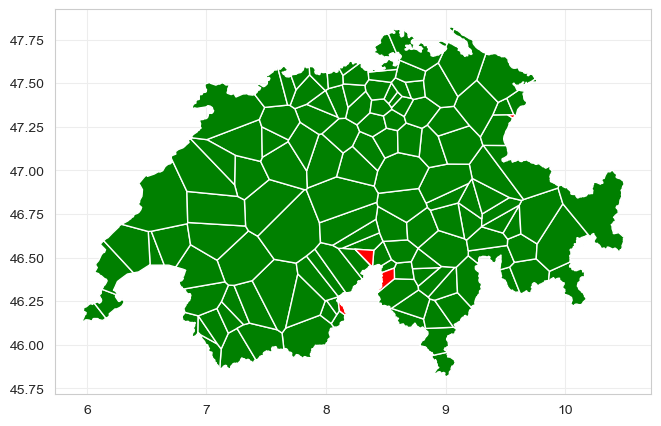

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
gdf_voronoi_nexuse_nodes_latlon[
    gdf_voronoi_nexuse_nodes_latlon["# idIntBus"].isin(da_pv_ch_grouped.idIntBus.values)
].plot(ax=ax, color="green")
gdf_voronoi_nexuse_nodes_latlon[
    ~gdf_voronoi_nexuse_nodes_latlon["# idIntBus"].isin(
        da_pv_ch_grouped.idIntBus.values
    )
].plot(ax=ax, color="red")

## Clean

In [11]:
from src.conversion_energy.aggregate_data import (
    create_geodataframe_climate_grid,
    match_point_to_unique_polygon,
)

In [ ]:
gdf_voronoi_nexuse_nodes = gpd.read_file(
    path_energy_ch / "gis_nexuse" / "Voronoi_2050_revised_clipped.shp"
)
gdf_voronoi_nexuse_nodes_latlon = gdf_voronoi_nexuse_nodes.to_crs("EPSG:4326")
buffered_voronoi = gdf_voronoi_nexuse_nodes_latlon.copy()
buffered_voronoi["geometry"] = buffered_voronoi.geometry.apply(
    lambda geom: geom.buffer(0.04, cap_style=3, resolution=16)
)

gdf_climate_grid = create_geodataframe_climate_grid(ds_rsds_bc_subset)

In [ ]:
point_to_polygon_map = match_point_to_unique_polygon(
    gdf_climate_grid, buffered_voronoi, "# idIntBus", buffer_distance=0.01
)

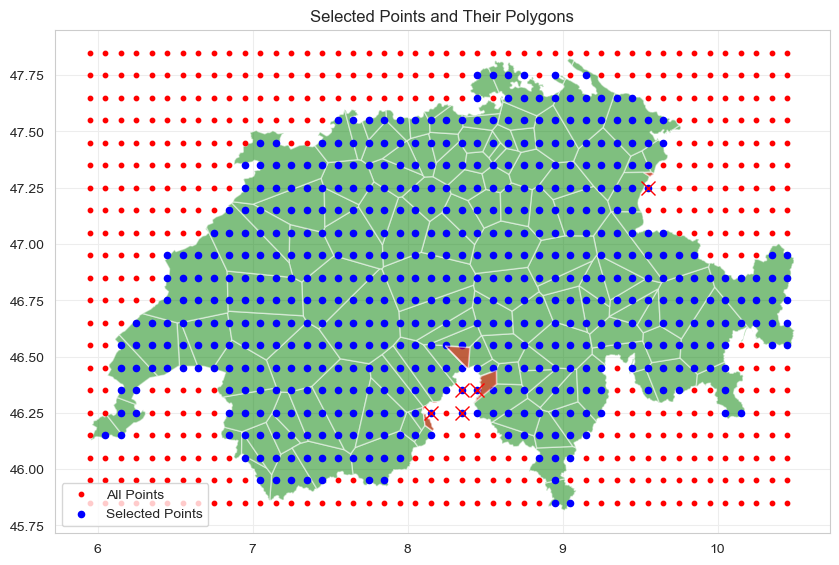

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))

# Highlight the selected polygons
selected_polygons = gdf_voronoi_nexuse_nodes_latlon[
    gdf_voronoi_nexuse_nodes_latlon["# idIntBus"].isin(point_to_polygon_map.values())
]
selected_polygons.plot(ax=ax, color="green", alpha=0.5)

# Plot all points
gdf_climate_grid.plot(ax=ax, color="red", markersize=10, label="All Points")

# Highlight the selected points
selected_points = gdf_climate_grid[
    gdf_climate_grid.apply(
        lambda row: (row["lat"], row["lon"]) in point_to_polygon_map, axis=1
    )
]
selected_points.plot(ax=ax, color="blue", markersize=20, label="Selected Points")

# Highlight the most difficult point/polygons
difficult_polygons = [75, 56, 126, 176, 175]
for polygon in difficult_polygons:
    p = next(
        (
            point
            for point, polygon_id in point_to_polygon_map.items()
            if polygon_id == polygon
        ),
        None,
    )
    plt.plot(p[1], p[0], "x", color="red", markersize=10)
    gdf_voronoi_nexuse_nodes_latlon[
        gdf_voronoi_nexuse_nodes_latlon["# idIntBus"] == polygon
    ].plot(ax=ax, color="red", alpha=0.5)

# Add legend and title
ax.legend()
ax.set_title("Selected Points and Their Polygons")
plt.show()

In [ ]:
gdf_point_in_voronoi = gpd.sjoin(
    gdf_climate_grid, buffered_voronoi, how="left", predicate="intersects"
).dropna()
gdf_point_in_voronoi

,geometry,lat,lon,index_right,# idIntBus,BusName,SwissgridN,Country,SubRegion,ZoneId,...,Vmin,Vmax,StartYr,EndYr,DemandShar,WindShare,SolarShare,idDistProf,X_Coord,Y_Coord
12,POINT (7.15000 45.85000),45.85,7.15,1.0,26.0,CH_Fionnay_FFM_220,SFIONF2A,CH,VS,2.0,...,0.9,1.2,2015.0,2100.0,0.0011,0.0,0.0,66.0,590018.0,97892.6
30,POINT (8.95000 45.85000),45.85,8.95,0.0,153.0,CH_Mendrisio_150,SMENDR3A,CH,TI,2.0,...,0.9,1.2,2015.0,2100.0,0.0062,0.0,0.0,193.0,719083.0,80433.0
31,POINT (9.05000 45.85000),45.85,9.05,0.0,153.0,CH_Mendrisio_150,SMENDR3A,CH,TI,2.0,...,0.9,1.2,2015.0,2100.0,0.0062,0.0,0.0,193.0,719083.0,80433.0
57,POINT (7.05000 45.95000),45.95,7.05,2.0,12.0,CH_Vallorcine_220,SVALLO2A,CH,VS,2.0,...,0.9,1.2,2015.0,2100.0,0.0004,0.0,0.0,52.0,562196.0,100097.0
58,POINT (7.15000 45.95000),45.95,7.15,2.0,12.0,CH_Vallorcine_220,SVALLO2A,CH,VS,2.0,...,0.9,1.2,2015.0,2100.0,0.0004,0.0,0.0,52.0,562196.0,100097.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
904,POINT (8.95000 47.75000),47.75,8.95,133.0,92.0,CH_Schlattingen_220,SSCHLA2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0104,0.0,0.0,132.0,700492.0,279572.0
905,POINT (9.05000 47.75000),47.75,9.05,131.0,110.0,CH_Weinfelden_220,SWEINF2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0147,0.0,0.0,150.0,724495.0,269165.0
906,POINT (9.15000 47.75000),47.75,9.15,131.0,110.0,CH_Weinfelden_220,SWEINF2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0147,0.0,0.0,150.0,724495.0,269165.0
907,POINT (9.25000 47.75000),47.75,9.25,131.0,110.0,CH_Weinfelden_220,SWEINF2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0147,0.0,0.0,150.0,724495.0,269165.0


In [18]:
len(np.unique(gdf_point_in_voronoi["# idIntBus"]))

134

In [26]:
gdf_point_in_voronoi

,geometry,lat,lon,index_right,# idIntBus,BusName,SwissgridN,Country,SubRegion,ZoneId,...,Vmin,Vmax,StartYr,EndYr,DemandShar,WindShare,SolarShare,idDistProf,X_Coord,Y_Coord
12,POINT (7.15000 45.85000),45.85,7.15,1.0,26.0,CH_Fionnay_FFM_220,SFIONF2A,CH,VS,2.0,...,0.9,1.2,2015.0,2100.0,0.0011,0.0,0.0,66.0,590018.0,97892.6
30,POINT (8.95000 45.85000),45.85,8.95,0.0,153.0,CH_Mendrisio_150,SMENDR3A,CH,TI,2.0,...,0.9,1.2,2015.0,2100.0,0.0062,0.0,0.0,193.0,719083.0,80433.0
31,POINT (9.05000 45.85000),45.85,9.05,0.0,153.0,CH_Mendrisio_150,SMENDR3A,CH,TI,2.0,...,0.9,1.2,2015.0,2100.0,0.0062,0.0,0.0,193.0,719083.0,80433.0
57,POINT (7.05000 45.95000),45.95,7.05,2.0,12.0,CH_Vallorcine_220,SVALLO2A,CH,VS,2.0,...,0.9,1.2,2015.0,2100.0,0.0004,0.0,0.0,52.0,562196.0,100097.0
58,POINT (7.15000 45.95000),45.95,7.15,2.0,12.0,CH_Vallorcine_220,SVALLO2A,CH,VS,2.0,...,0.9,1.2,2015.0,2100.0,0.0004,0.0,0.0,52.0,562196.0,100097.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
905,POINT (9.05000 47.75000),47.75,9.05,133.0,92.0,CH_Schlattingen_220,SSCHLA2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0104,0.0,0.0,132.0,700492.0,279572.0
906,POINT (9.15000 47.75000),47.75,9.15,131.0,110.0,CH_Weinfelden_220,SWEINF2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0147,0.0,0.0,150.0,724495.0,269165.0
907,POINT (9.25000 47.75000),47.75,9.25,131.0,110.0,CH_Weinfelden_220,SWEINF2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0147,0.0,0.0,150.0,724495.0,269165.0
946,POINT (8.55000 47.85000),47.85,8.55,133.0,92.0,CH_Schlattingen_220,SSCHLA2A,CH,TG,2.0,...,0.9,1.2,2015.0,2100.0,0.0104,0.0,0.0,132.0,700492.0,279572.0


In [ ]:
from collections import defaultdict

# Create a mapping of lat/lon points to all intersecting polygon IDs
point_to_polygons_map = defaultdict(list)
for point, polygon_id in point_to_polygon_map.items():
    intersecting_polygons = buffered_voronoi[
        buffered_voronoi.geometry.intersects(Point(point[1], point[0]))
    ]
    for _, polygon in intersecting_polygons.iterrows():
        point_to_polygons_map[point].append(polygon["# idIntBus"])

# Create a 2D array of lists of polygon IDs corresponding to each grid point
lat_lon_to_polygons = np.empty((len(da_pv_ch.lat), len(da_pv_ch.lon)), dtype=object)

for lat_idx, lat in enumerate(da_pv_ch.lat.values):
    for lon_idx, lon in enumerate(da_pv_ch.lon.values):
        lat_lon_to_polygons[lat_idx, lon_idx] = point_to_polygons_map.get(
            (lat, lon), []
        )

# Create a DataArray to store the mapping
lat_lon_to_polygons_da = xr.DataArray(
    lat_lon_to_polygons,
    dims=["lat", "lon"],
    coords={"lat": da_pv_ch.lat, "lon": da_pv_ch.lon},
    name="polygon_ids",
)

In [ ]:
# Initialize a dictionary to store aggregated PV data for each polygon
aggregated_pv_data = defaultdict(list)

# Iterate over all grid points and distribute PV data to intersecting polygons
for lat_idx, lat in enumerate(da_pv_ch.lat.values):
    for lon_idx, lon in enumerate(da_pv_ch.lon.values):
        polygon_ids = lat_lon_to_polygons_da.values[lat_idx][lon_idx]
        if len(polygon_ids) > 0:
            pv_data = da_pv_ch.isel(lat=lat_idx, lon=lon_idx).drop_vars(["lat", "lon"])
            for polygon_id in polygon_ids:
                aggregated_pv_data[polygon_id].append(pv_data)

# Calculate the mean PV data for each polygon
aggregated_pv_data_mean = {
    polygon_id: xr.concat(data_list, dim="grid_point").mean(dim="grid_point")
    for polygon_id, data_list in aggregated_pv_data.items()
}

# Combine the aggregated data into a single xarray Dataset
da_pv_ch_grouped = xr.concat(
    [
        data.assign_coords(polygon_id=polygon_id)
        for polygon_id, data in aggregated_pv_data_mean.items()
    ],
    dim="polygon_id",
)

# Resulting dataset
da_pv_ch_grouped

<xarray.Dataset> Size: 6MB
Dimensions:     (time: 5840, polygon_id: 135)
Coordinates:
  * time        (time) datetime64[ns] 47kB 2020-01-01 ... 2021-12-31T21:00:00
  * polygon_id  (polygon_id) int64 1kB 153 12 26 165 29 44 ... 65 57 73 74 89 92
Data variables:
    ac_power    (polygon_id, time) float64 6MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0

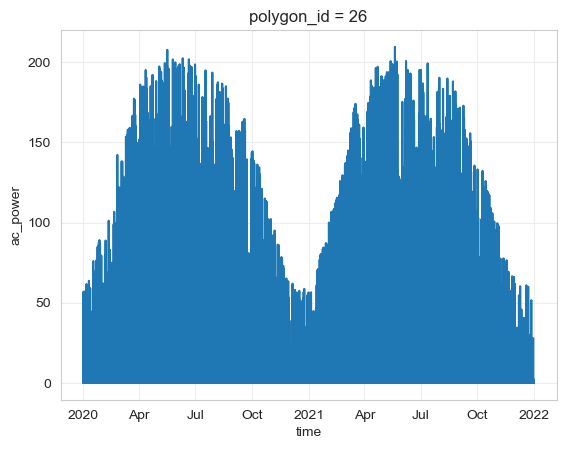

In [50]:
da_pv_ch_grouped.sel(polygon_id=26).ac_power.plot()

# Load computed PV potential

In [4]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"
path_pv = path_energy_ch / "solar" / f"pv_{climate_model_chain}_{climate_scenario}.zarr"
path_pv_sensitivity_test = (
    path_energy_ch
    / "solar"
    / f"pv_sensitivity_test_{climate_model_chain}_{climate_scenario}.zarr"
)
extent_ch = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}

In [5]:
ds_pv = xr.open_zarr(path_pv, chunks="auto")

In [6]:
ds_pv_sensitivity_test = xr.open_zarr(path_pv_sensitivity_test, chunks="auto")

In [7]:
ds_orog = sel_extent(
    xr.open_dataset(
        sorted(
            (
                path_data_processed
                / "cordex_processed"
                / f"{climate_model_chain}_{climate_scenario}"
                / "regridded"
                / "fx"
            ).glob("*.nc")
        )[0]
    ),
    extent_ch,
)

In [31]:
gdf_regions_ch = gpd.read_file(
    path_data_processed / "maps" / "regions_ch" / "PRODREG.shp"
).to_crs("EPSG:4326")
regions_ch = regionmask.from_geopandas(gdf_regions_ch, names="ProdregN_3")
regions_ch_mask = regions_ch.mask(ds_orog.orog)

## Visual Inspection

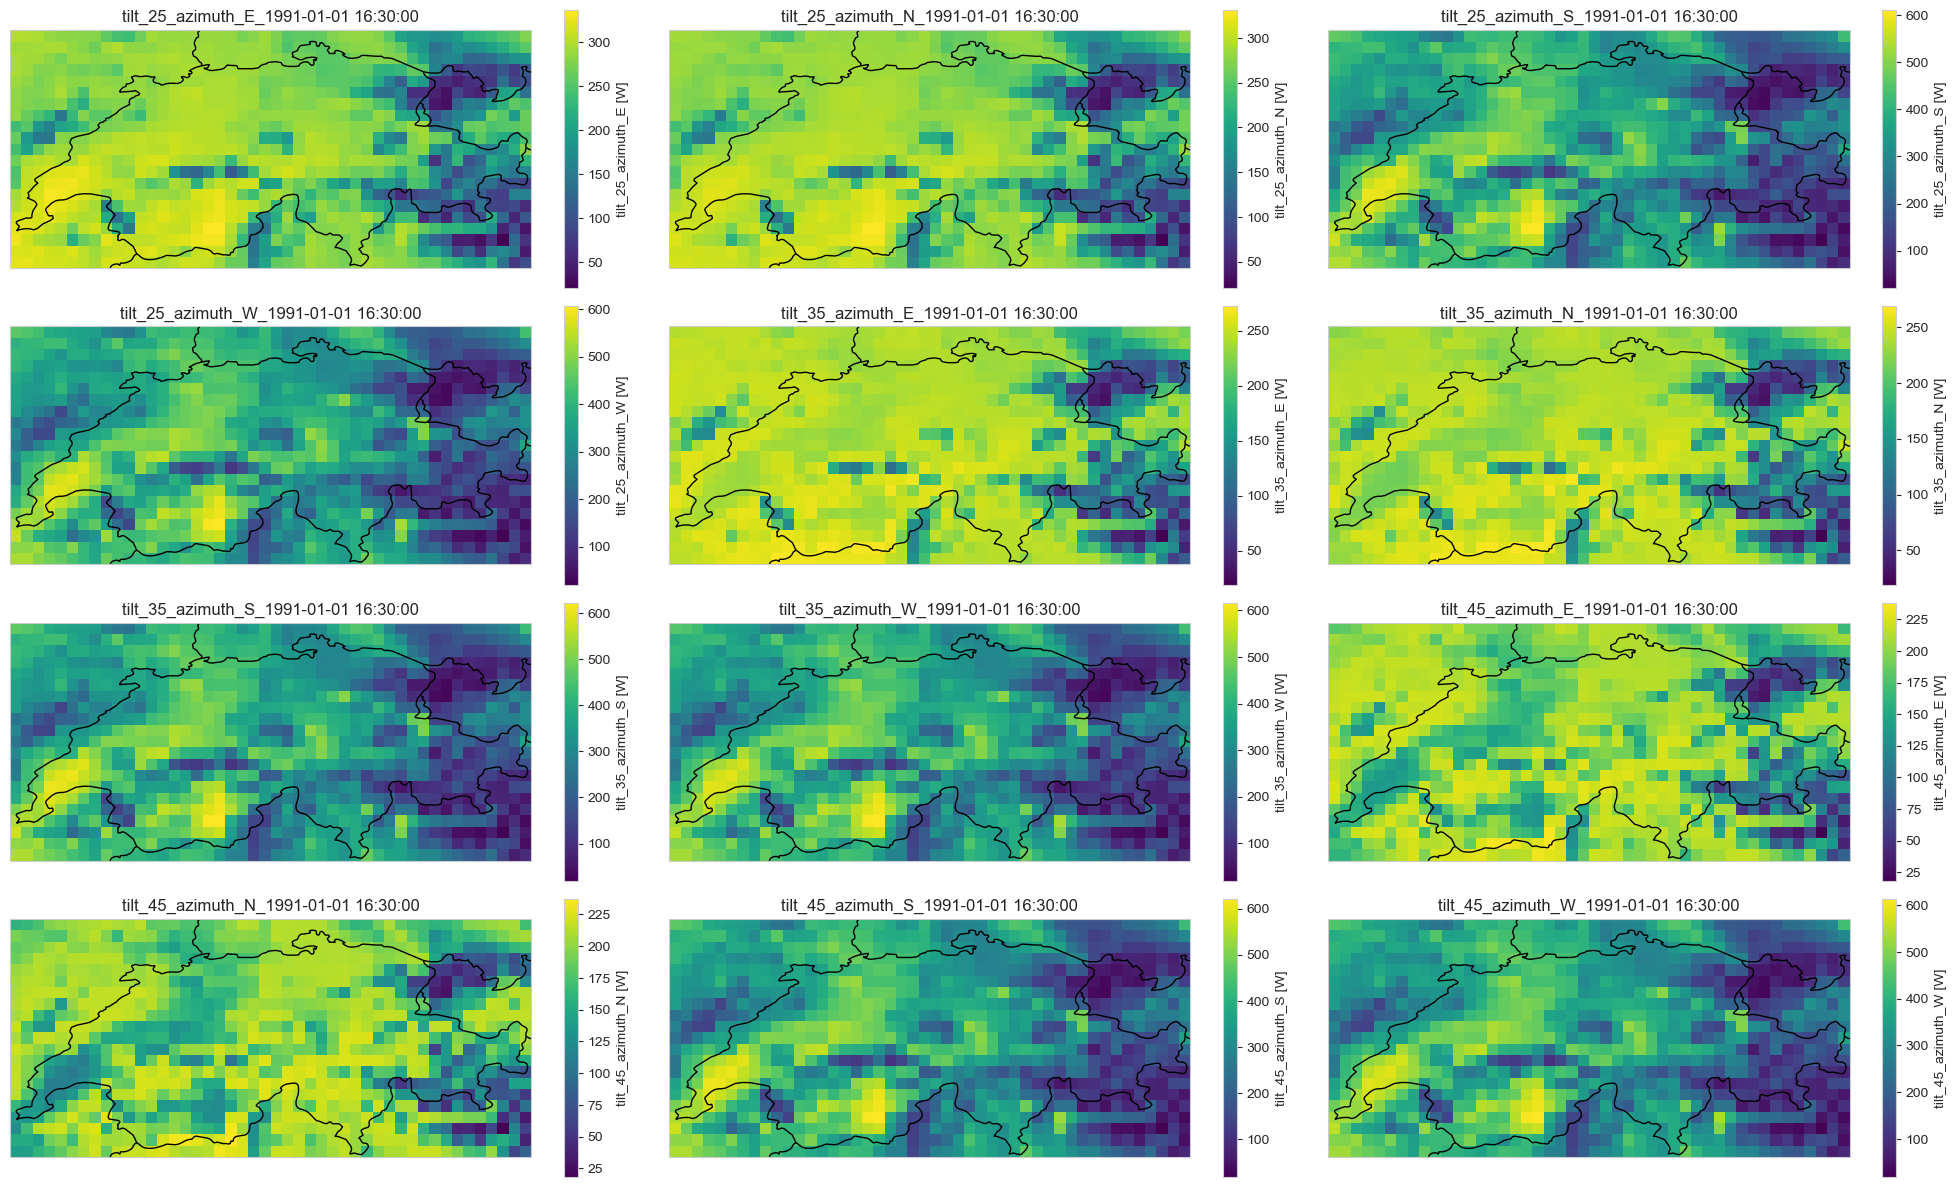

In [ ]:
# Extract variable names from the dataset
variables = list(ds_pv.data_vars)

# Define the number of rows and columns for the grid
n_cols = 3
n_rows = (len(variables) + n_cols - 1) // n_cols  # Calculate rows needed

# Create subplots
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, 3 * n_rows),
    subplot_kw={"projection": ccrs.PlateCarree()},
)
axes = axes.flatten()  # Flatten the axes array for easier indexing

# Loop through each variable and plot its first time step
for i, var in enumerate(variables):
    ax = axes[i]
    ds_pv[var].sel(time="1991-09-01 13:30").plot(ax=ax)
    ax.add_feature(
        cfeature.BORDERS, linestyle="-", edgecolor="black"
    )  # Add country borders
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")  # Add coastlines
    ax.set_title(f"{var}_{pd.to_datetime(ds_pv[var].isel(time=5).time.item())}")


# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

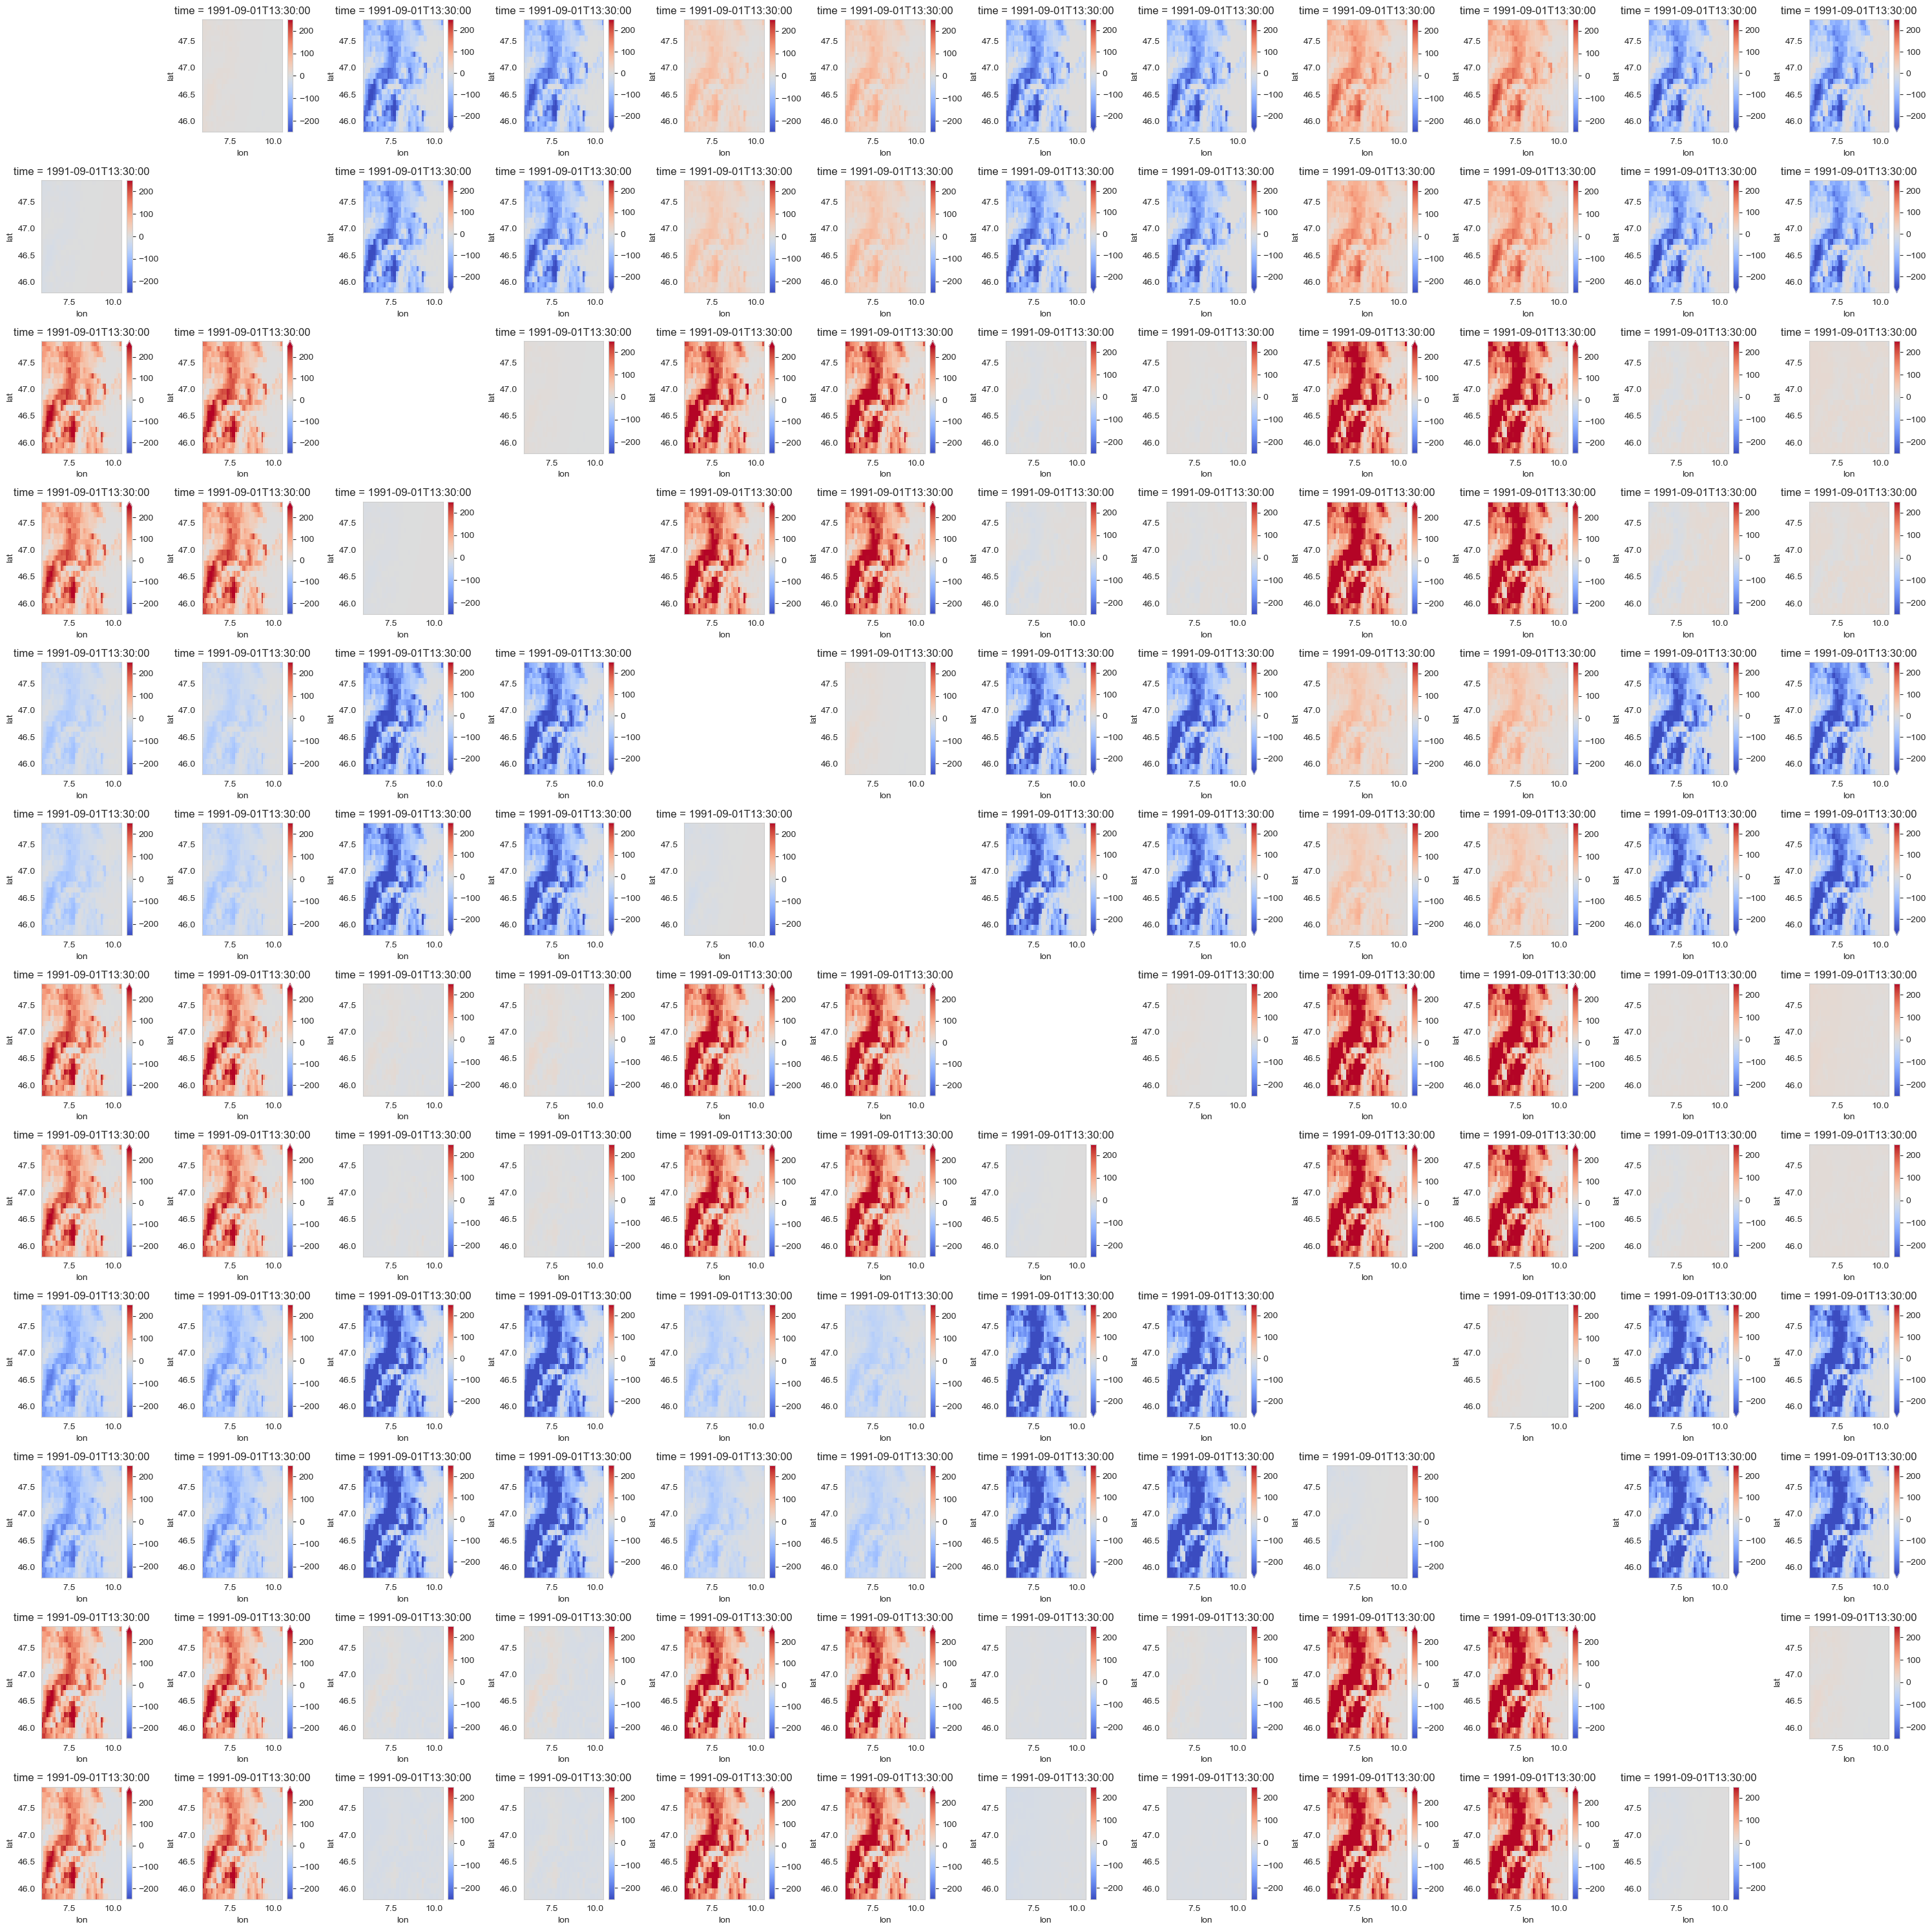

In [ ]:
# Extract variable names from the dataset
variables = list(ds_pv.data_vars)

# Create subplots for differences
fig, axes = plt.subplots(len(variables), len(variables), figsize=(30, 30))

# Loop through each variable and compute differences
for i, var1 in enumerate(variables):
    for j, var2 in enumerate(variables):
        if i != j:
            # Compute the difference
            diff = ds_pv[var1].sel(time="1991-09-01 13:30") - ds_pv[var2].sel(
                time="1991-09-01 13:30"
            )

            # Plot the difference
            ax = axes[i, j]
            diff.plot(ax=ax, vmin=-250, vmax=250, cmap="coolwarm")
        else:
            # Leave diagonal plots empty
            axes[i, j].axis("off")

# Adjust layout
plt.tight_layout()
plt.show()

## Sensitivity test

In [ ]:
# Sum per day
ds_daily_sum = ds_pv_sensitivity_test.resample(time="1D").sum()

# Compute yearly mean
ds_yearly_mean = ds_daily_sum.resample(time="1YE").mean()

# Compute the mean across all years for each variable
mean_across_years = ds_yearly_mean.mean().compute()

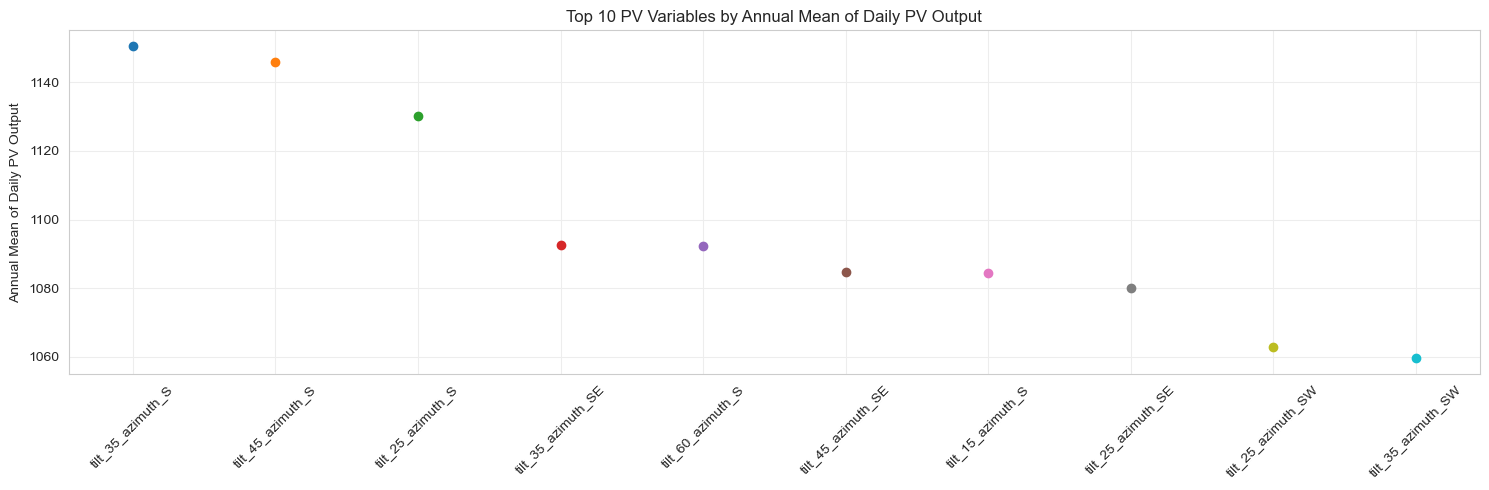

In [ ]:
sorted_vars = sorted(
    mean_across_years.data_vars,
    key=lambda var: mean_across_years[var].item(),
    reverse=True,
)
ds_sorted_by_mean = mean_across_years[sorted_vars]

# Select the top 10 variables
top_10 = ds_sorted_by_mean[sorted_vars[:10]]

# Plot the top 10 variables in a bar plot
fig, ax = plt.subplots(figsize=(15, 5))
for var in top_10.data_vars:
    ax.scatter(x=var, y=top_10[var])
plt.title("Top 10 PV Variables by Annual Mean of Daily PV Output")
plt.ylabel("Annual Mean of Daily PV Output")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Analysis

In [8]:
selected_var = "tilt_35_azimuth_S"

reference_period = slice("1991", "2020")
future_period = slice("2021", "2050")

### Trend

Trend: -0.0964 per year
95% Confidence Interval: [-0.2873, 0.0945]


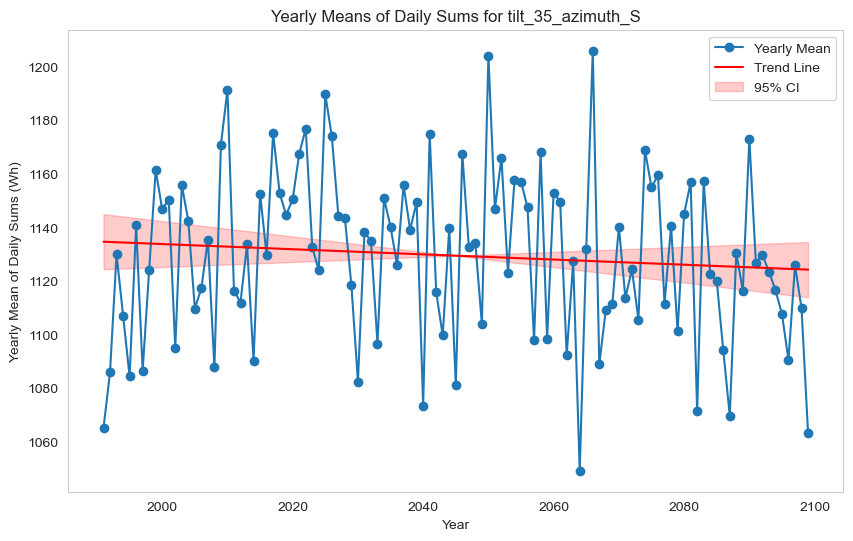

In [9]:
import statsmodels.api as sm

# Compute yearly means of daily sums for the variable
ds_pv_yearly_mean = (
    ds_pv[[selected_var]]
    .resample(time="1D")
    .sum()
    .resample(time="1YE")
    .mean()
    .mean(dim=["lat", "lon"])
)

# Extract time and values
years = ds_pv_yearly_mean.time.dt.year.values
values = ds_pv_yearly_mean[selected_var].values.reshape(-1)

# Fit a linear regression model
X = sm.add_constant(years)
model = sm.OLS(values, X).fit()

# Extract the trend (slope) and confidence interval
trend = model.params[1]
conf_int = model.conf_int(alpha=0.05)
lower_bound, upper_bound = conf_int[1]

# Print the results
print(f"Trend: {trend:.4f} per year")
print(f"95% Confidence Interval: [{lower_bound:.4f}, {upper_bound:.4f}]")

# Generate predictions and confidence intervals
predicted = model.predict(X)
ci_lower = predicted + (lower_bound - trend) * (X[:, 1] - X[:, 1].mean())
ci_upper = predicted + (upper_bound - trend) * (X[:, 1] - X[:, 1].mean())

# Plot the yearly means, regression line, and confidence interval
plt.figure(figsize=(10, 6))
plt.plot(years, values, label="Yearly Mean", marker="o")
plt.plot(years, predicted, label="Trend Line", color="red")
plt.fill_between(years, ci_lower, ci_upper, color="red", alpha=0.2, label="95% CI")
plt.xlabel("Year")
plt.ylabel("Yearly Mean of Daily Sums (Wh)")
plt.title("Yearly Means of Daily Sums for tilt_35_azimuth_S")
plt.grid()
plt.legend()
plt.show()

In [10]:
ds_pv_monthly_sum = (
    ds_pv[[selected_var]]
    .resample(time="1ME")
    .sum()
)

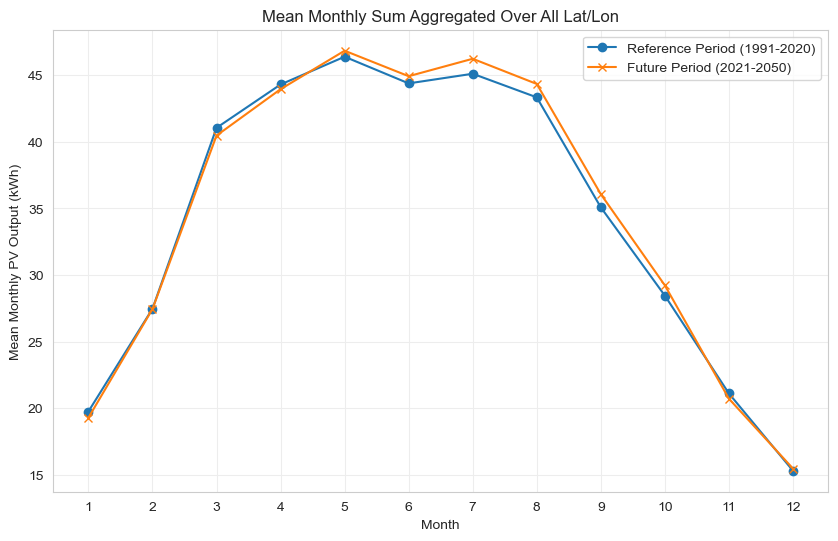

In [11]:
# Calculate the mean of monthly sums for the reference and future periods over all lat/lon
mean_monthly_reference_agg = ds_pv_monthly_sum.sel(time=reference_period).groupby("time.month").mean().mean(dim=["lat", "lon"]) * 1e-3
mean_monthly_future_agg = ds_pv_monthly_sum.sel(time=future_period).groupby("time.month").mean().mean(dim=["lat", "lon"]) * 1e-3

# Plot the results
plt.figure(figsize=(10, 6))
mean_monthly_reference_agg[selected_var].plot(label="Reference Period (1991-2020)", marker="o")
mean_monthly_future_agg[selected_var].plot(label="Future Period (2021-2050)", marker="x")
plt.title("Mean Monthly Sum Aggregated Over All Lat/Lon")
plt.ylabel("Mean Monthly PV Output (kWh)")
plt.xlabel("Month")
plt.xticks(ticks=mean_monthly_reference_agg["month"].values, labels=mean_monthly_reference_agg["month"].values)
plt.legend()
plt.show()


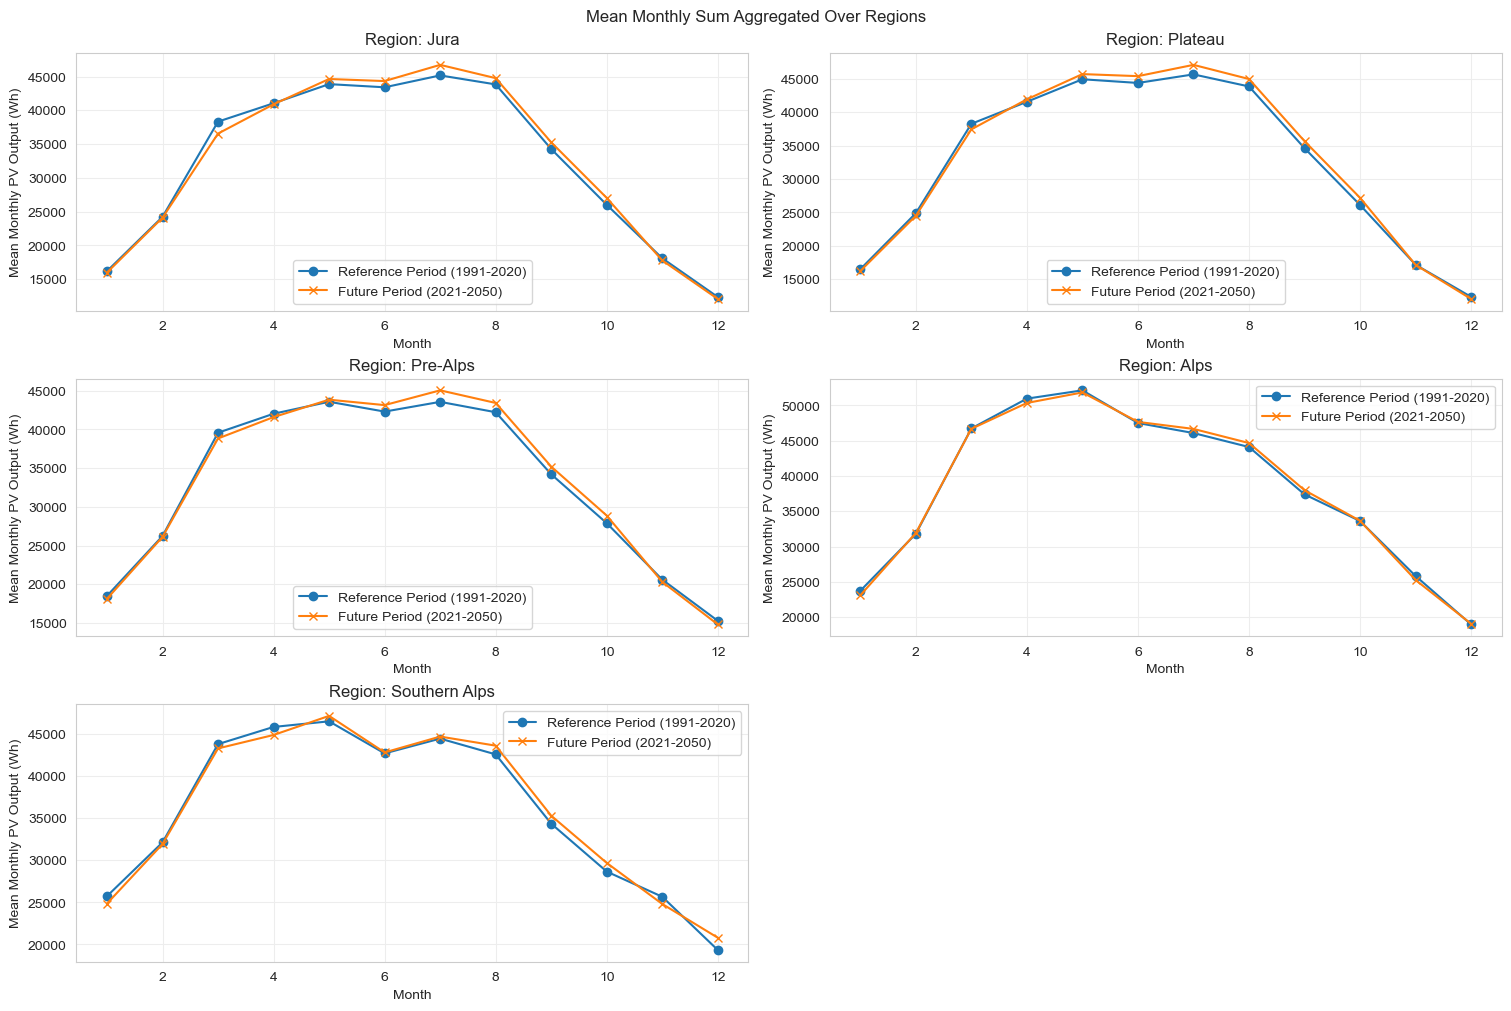

In [37]:
# Calculate the mean of monthly sums for the reference and future periods grouped by regions
mean_monthly_reference_regions = ds_pv_monthly_sum.sel(time=reference_period).groupby("time.month").mean().groupby(regions_ch_mask).mean(dim=("lat", "lon"))
mean_monthly_future_regions = ds_pv_monthly_sum.sel(time=future_period).groupby("time.month").mean().groupby(regions_ch_mask).mean(dim=("lat", "lon"))

# Plot the results for each region
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 10), constrained_layout=True)
axes = axes.flatten()

for i, region in enumerate(gdf_regions_ch["ProdregN_3"].values):
    ax = axes[i]
    mean_monthly_reference_regions.sel(mask=i)[selected_var].plot(ax=ax, label="Reference Period (1991-2020)", marker="o")
    mean_monthly_future_regions.sel(mask=i)[selected_var].plot(ax=ax, label="Future Period (2021-2050)", marker="x")
    ax.set_title(f"Region: {region}")
    ax.set_ylabel("Mean Monthly PV Output (Wh)")
    ax.set_xlabel("Month")
    ax.legend()

# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Mean Monthly Sum Aggregated Over Regions")
plt.show()


### Mean change

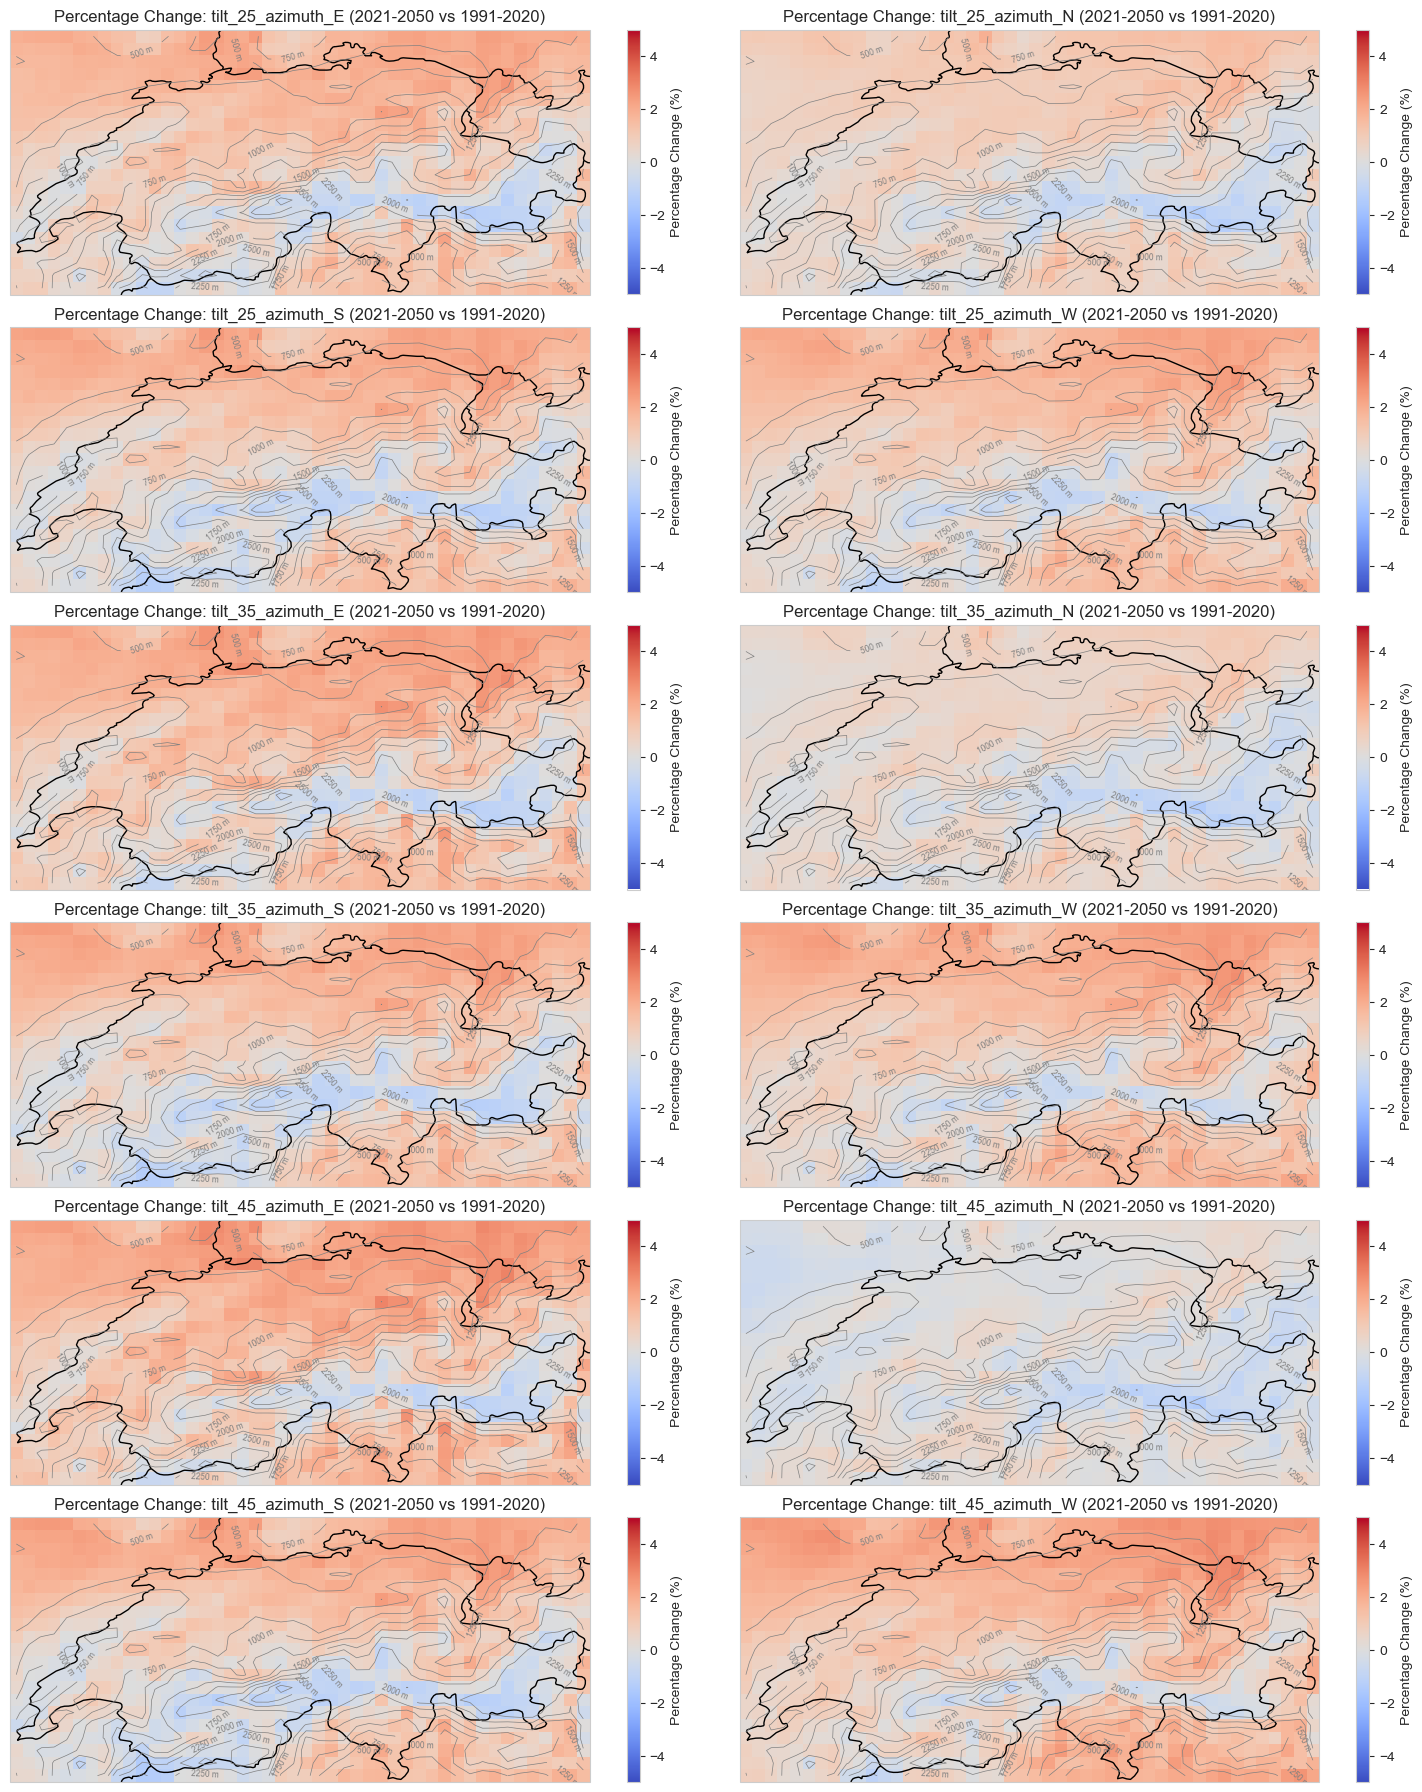

In [ ]:
# Calculate the mean daily PV for each period
mean_reference = (
    ds_pv.sel(time=reference_period).resample(time="1D").sum().mean(dim="time")
)
mean_future = ds_pv.sel(time=future_period).resample(time="1D").sum().mean(dim="time")

# Compute the difference between the future and reference periods
percentage_change = ((mean_future - mean_reference) / mean_reference) * 100

# Plot the percentage change for each turbine type
n_cols = 2
n_rows = (len(variables) + n_cols - 1) // n_cols  # Calculate rows needed

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 3 * n_rows),
    subplot_kw={"projection": ccrs.PlateCarree()},
)
axes = axes.flatten()

for i, var in enumerate(variables):
    ax = axes[i]
    percentage_change[var].plot(
        ax=ax,
        cmap="coolwarm",
        vmin=-5,
        vmax=5,
        cbar_kwargs={"label": "Percentage Change (%)"},
    )
    ax.set_title(f"Percentage Change: {var} (2021-2050 vs 1991-2020)")
    ax.add_feature(
        cfeature.BORDERS, linestyle="-", edgecolor="black"
    )  # Add country borders
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")  # Add coastlines

    # Add isolines of topography
    cs = ax.contour(
        ds_orog.lon,
        ds_orog.lat,
        ds_orog.orog,
        levels=10,
        colors="grey",
        linewidths=0.5,
        transform=ccrs.PlateCarree(),
    )
    ax.clabel(cs, inline=True, fontsize=6, fmt="%d m")

# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

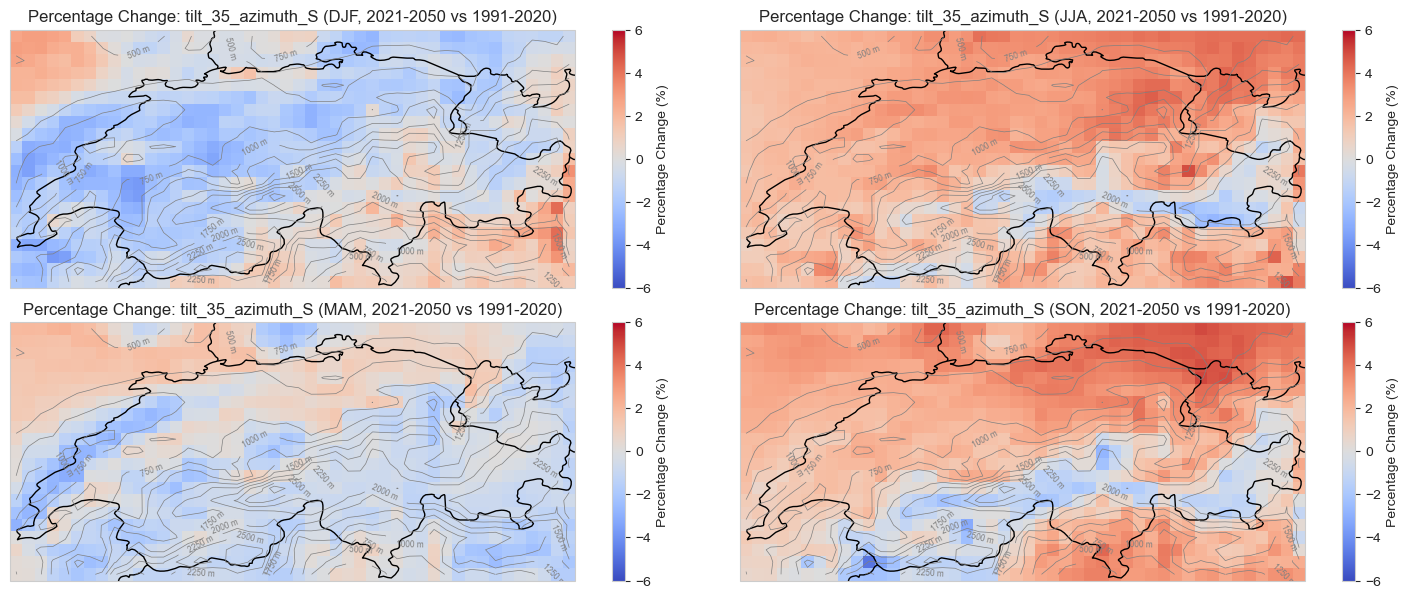

In [ ]:
# Group data by season and calculate the mean for each season
seasonal_reference = (
    ds_pv[[selected_var]]
    .sel(time=reference_period)
    .groupby("time.season")
    .mean(dim="time")
)
seasonal_future = (
    ds_pv[[selected_var]]
    .sel(time=future_period)
    .groupby("time.season")
    .mean(dim="time")
)

# Compute the percentage change for each season
seasonal_percentage_change = (
    (seasonal_future - seasonal_reference) / seasonal_reference
) * 100

# Plot the percentage change for each turbine type and season
n_cols = 2
n_rows = 2

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 3 * n_rows),
    subplot_kw={"projection": ccrs.PlateCarree()},
)
axes = axes.flatten()

for i, season in enumerate(seasonal_percentage_change.season.values):
    ax = axes[i]
    seasonal_percentage_change[selected_var].sel(season=season).plot(
        ax=ax,
        vmin=-6,
        vmax=6,
        cmap="coolwarm",
        cbar_kwargs={"label": "Percentage Change (%)"},
    )
    ax.set_title(
        f"Percentage Change: {selected_var} ({season}, 2021-2050 vs 1991-2020)"
    )
    ax.add_feature(
        cfeature.BORDERS, linestyle="-", edgecolor="black"
    )  # Add country borders
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")  # Add coastlines
    # Add isolines of topography
    cs = ax.contour(
        ds_orog.lon,
        ds_orog.lat,
        ds_orog.orog,
        levels=10,
        colors="grey",
        linewidths=0.5,
        transform=ccrs.PlateCarree(),
    )
    ax.clabel(cs, inline=True, fontsize=6, fmt="%d m")

plt.tight_layout()
plt.show()

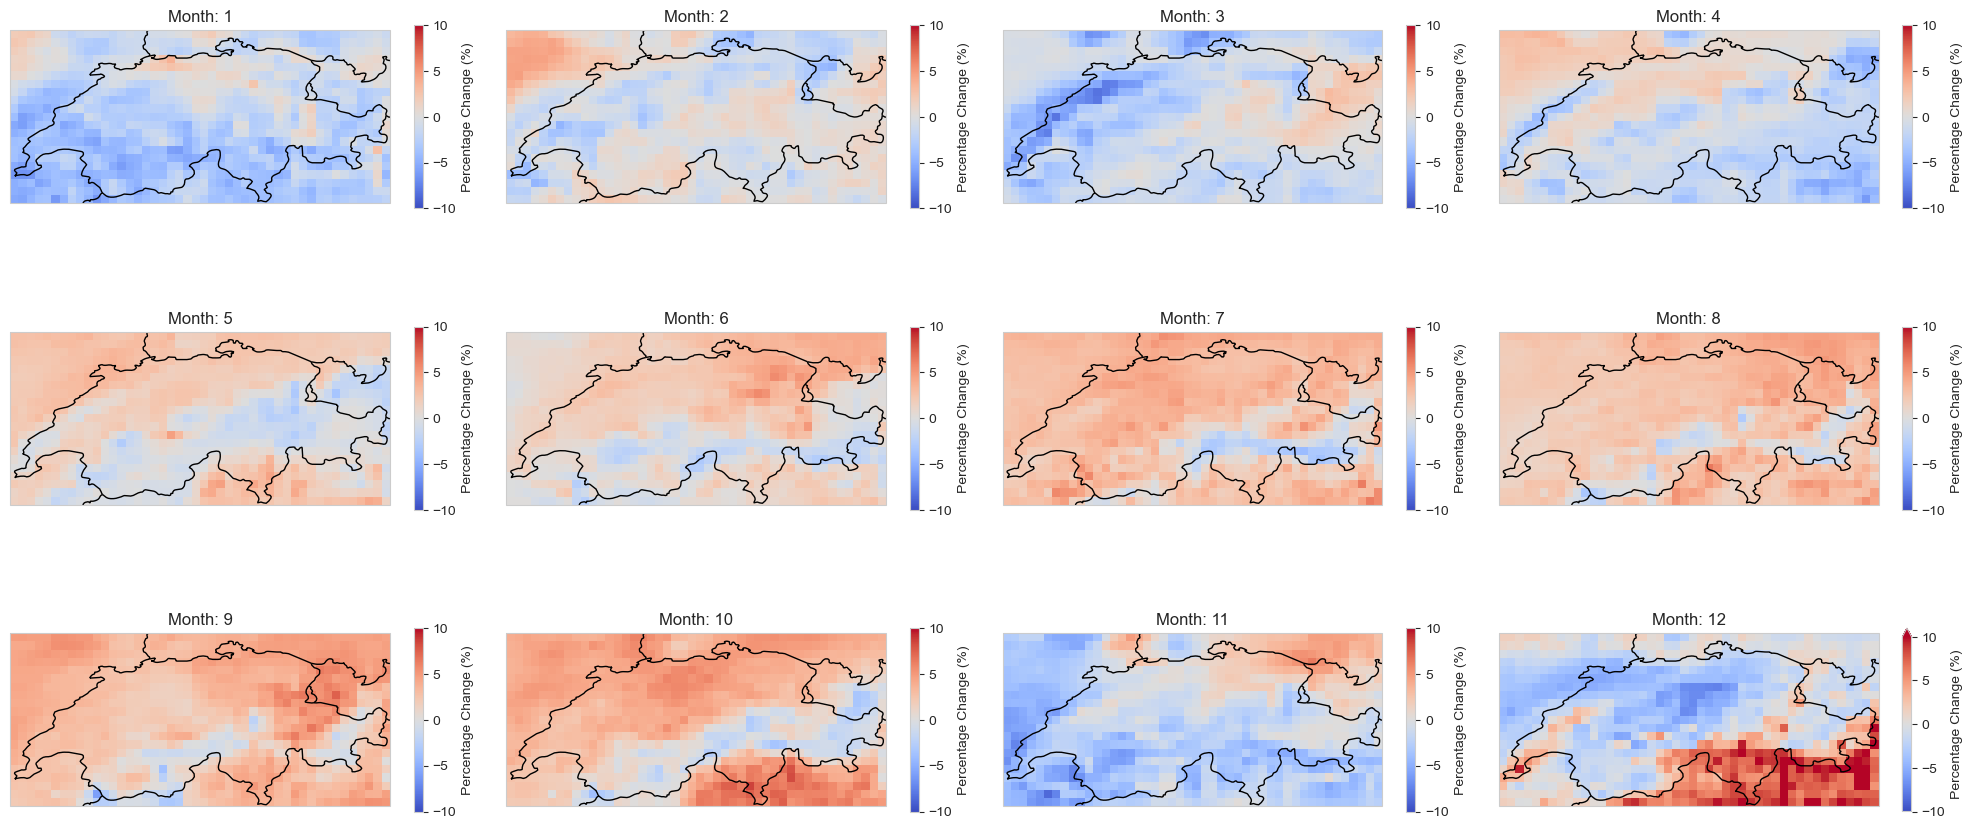

In [15]:
# Compute the monthly mean of monthly sums for the reference and future periods
mean_monthly_reference = ds_pv_monthly_sum.sel(time=reference_period).groupby("time.month").mean()
mean_monthly_future = ds_pv_monthly_sum.sel(time=future_period).groupby("time.month").mean()

# Compute the percentage change
percentage_change_monthly = ((mean_monthly_future - mean_monthly_reference) / mean_monthly_reference) * 100

# Plot the percentage change for each month
fig, axes = plt.subplots(
    3, 4, figsize=(20, 10), subplot_kw={"projection": ccrs.PlateCarree()}
)
axes = axes.flatten()

for i, month in enumerate(percentage_change_monthly.month.values):
    ax = axes[i]
    percentage_change_monthly[selected_var].sel(month=month).plot(
        ax=ax,
        cmap="coolwarm",
        cbar_kwargs={"label": "Percentage Change (%)", "shrink": 0.5},
        robust=True,
        vmin=-10,
        vmax=10,
    )
    ax.set_title(f"Month: {month}")
    ax.add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")

# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

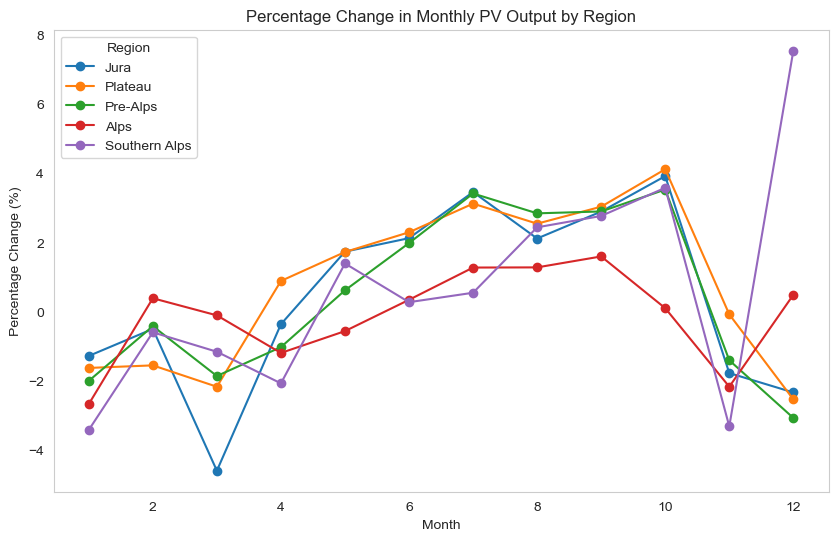

In [ ]:
mean_monthly_future_regions_ch = mean_monthly_future.groupby(regions_ch_mask).mean(dim=("lat", "lon"))
mean_monthly_future_regions_ch["mask"] = gdf_regions_ch["ProdregN_3"].values

# Group mean_monthly_reference by regions and calculate the mean
mean_monthly_reference_regions_ch = mean_monthly_reference.groupby(regions_ch_mask).mean(dim=("lat", "lon"))
mean_monthly_reference_regions_ch["mask"] = gdf_regions_ch["ProdregN_3"].values

# Calculate the percentage change
percentage_change_regions_ch = (
    (mean_monthly_future_regions_ch - mean_monthly_reference_regions_ch)
    / mean_monthly_reference_regions_ch
) * 100

# Plot the percentage change by month for each region
fig, ax = plt.subplots(figsize=(10, 6))
for region in percentage_change_regions_ch["mask"].values:
    percentage_change_regions_ch.sel(mask=region)[selected_var].plot(
        ax=ax, label=region, marker="o"
    )

plt.title("Percentage Change in Monthly PV Output by Region")
plt.xlabel("Month")
plt.ylabel("Percentage Change (%)")
plt.legend(title="Region")
plt.show()

### Variability

In [76]:
# Compute standard deviations for the reference and future periods
std_reference = ds_pv_yearly_mean.sel(time=reference_period).std()
std_future = ds_pv_yearly_mean.sel(time=future_period).std()

print(f"Standard Deviation (Reference Period): {std_reference[selected_var].values}")
print(f"Standard Deviation (Future Period): {std_future[selected_var].values}")

Standard Deviation (Reference Period): 30.59510662224905
Standard Deviation (Future Period): 31.482301917599877


In [ ]:
# 3. Perform Levene's test to compare variances
from scipy.stats import levene


reference_data = (
    ds_pv_yearly_mean[selected_var].sel(time=reference_period).values.flatten()
)
future_data = ds_pv_yearly_mean[selected_var].sel(time=future_period).values.flatten()

stat, p_value = levene(reference_data, future_data)
print(f"Levene's test for {var}: Statistic={stat}, p-value={p_value}")
if p_value < 0.05:
    print(f"Variability for {var} is significantly different between periods.")
else:
    print(f"No significant difference in variability for {var}.")

Levene's test for tilt_25_azimuth_E: Statistic=0.07256427473185519, p-value=0.7885951745469918
No significant difference in variability for tilt_25_azimuth_E.


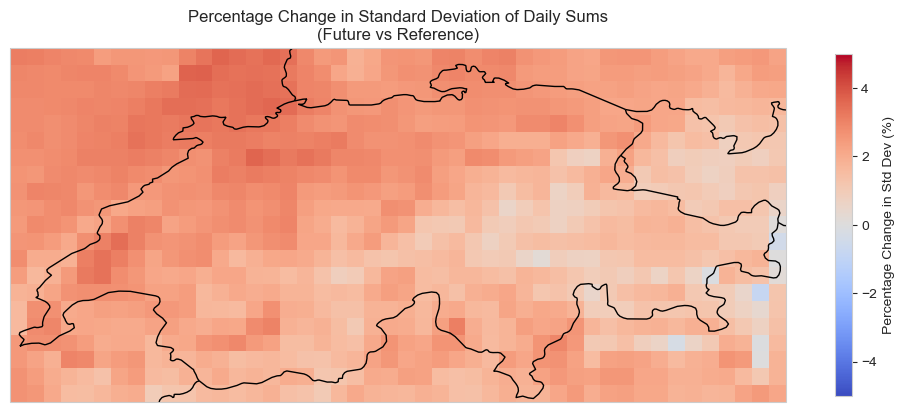

In [40]:
# Compute daily sums
ds_daily_sum = ds_pv.resample(time="1D").sum()

# Compute standard deviations for the reference and future periods
std_reference = ds_daily_sum.sel(time=reference_period).std(dim="time")
std_future = ds_daily_sum.sel(time=future_period).std(dim="time")

# Compute the percentage change
std_percentage_change = ((std_future - std_reference) / std_reference) * 100

# Plot the percentage change
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
std_percentage_change[selected_var].plot(
    ax=ax,
    cmap="coolwarm",
    vmin=-5,
    vmax=5,
    cbar_kwargs={"label": "Percentage Change in Std Dev (%)", "shrink": 0.6},
    robust=True,
)
ax.set_title("Percentage Change in Standard Deviation of Daily Sums\n(Future vs Reference)")
ax.add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
ax.add_feature(cfeature.COASTLINE, edgecolor="black")
plt.tight_layout()
plt.show()

### Upper and lower quantiles

In [88]:
ds_daily_sum = ds_pv[[selected_var]].resample(time="1D").sum().compute()
ds_daily_sum

<xarray.Dataset> Size: 308MB
Dimensions:            (time: 39812, lat: 21, lon: 46)
Coordinates:
  * lat                (lat) float64 168B 45.85 45.95 46.05 ... 47.75 47.85
  * lon                (lon) float64 368B 5.95 6.05 6.15 ... 10.25 10.35 10.45
  * time               (time) datetime64[ns] 318kB 1991-01-01 ... 2099-12-31
Data variables:
    tilt_35_azimuth_S  (time, lat, lon) float64 308MB 35.99 30.86 ... 73.45

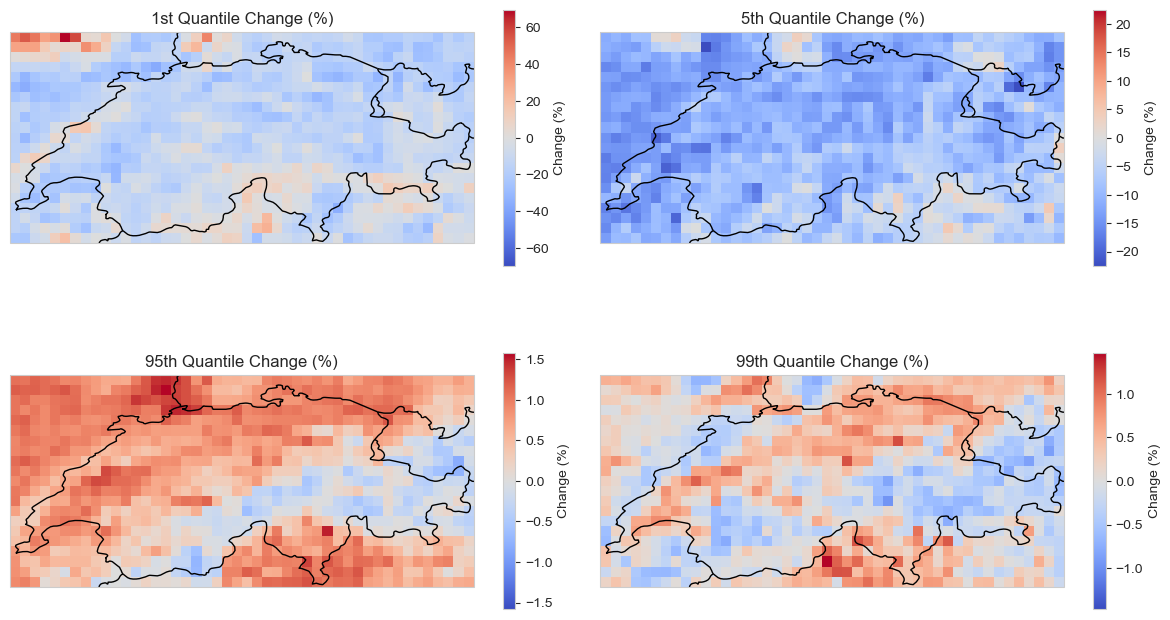

In [106]:
quantiles = [0.01, 0.05, 0.95, 0.99]
# Calculate the 5th and 95th quantiles for the reference period
quantiles_reference = ds_daily_sum.sel(time=reference_period).quantile(
    quantiles, dim="time"
)

# Calculate the 5th and 95th quantiles for the future period
quantiles_future = ds_daily_sum.sel(time=future_period).quantile(quantiles, dim="time")

# Compute the mean change for the 5th and 95th quantiles
mean_change_quantiles = (
    (quantiles_future - quantiles_reference) / quantiles_reference * 100
)

# Plot the mean changes for the 5th and 95th quantiles
fig, axes = plt.subplots(
    2, 2, figsize=(12, 8), subplot_kw={"projection": ccrs.PlateCarree()}
)
axes = axes.flatten()

for ax, quantile, title in zip(
    axes,
    quantiles,
    [
        "1st Quantile Change (%)",
        "5th Quantile Change (%)",
        "95th Quantile Change (%)",
        "99th Quantile Change (%)",
    ],
):
    mean_change_quantiles[selected_var].sel(quantile=quantile).plot(
        ax=ax, cmap="coolwarm", cbar_kwargs={"label": "Change (%)", "shrink": 0.6}
    )
    ax.set_title(title)
    ax.add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")

plt.tight_layout()
plt.show()

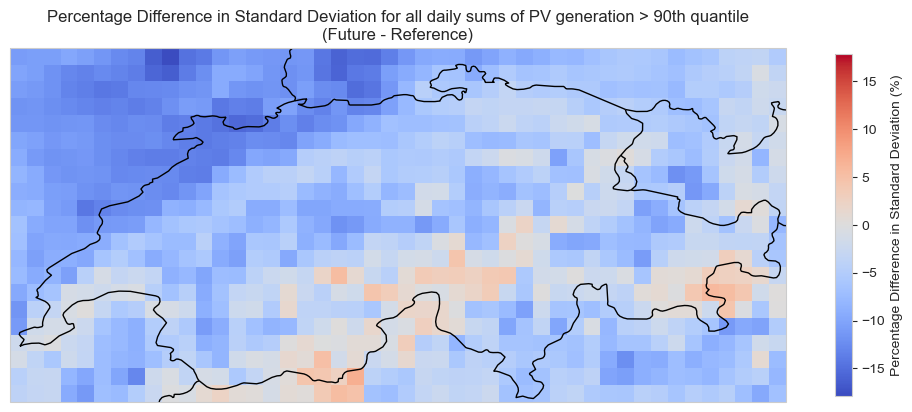

In [ ]:
# Define the quantile threshold
quantile_threshold = 0.90

# Select values above the quantile threshold for the reference period
above_quantile_reference = ds_daily_sum[selected_var].sel(time=reference_period).where(
    ds_daily_sum[selected_var].sel(time=reference_period) > ds_daily_sum[selected_var].sel(time=reference_period).quantile(quantile_threshold, dim="time")
)

# Compute the standard deviation for the reference period
std_above_quantile_reference = above_quantile_reference.std(dim="time")

# Select values above the quantile threshold for the future period
above_quantile_future = ds_daily_sum[selected_var].sel(time=future_period).where(
    ds_daily_sum[selected_var].sel(time=future_period) > ds_daily_sum[selected_var].sel(time=future_period).quantile(quantile_threshold, dim="time")
)

# Compute the standard deviation for the future period
std_above_quantile_future = above_quantile_future.std(dim="time")

# Compute the difference between the standard deviations
std_percentage_difference = (
    (std_above_quantile_future - std_above_quantile_reference)
    / std_above_quantile_reference
) * 100

# Plot the percentage difference
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})

std_percentage_difference.plot(
    ax=ax,
    cmap="coolwarm",
    cbar_kwargs={"label": "Percentage Difference in Standard Deviation (%)", "shrink": 0.6},
)
ax.set_title("Percentage Difference in Standard Deviation for all daily sums of PV generation > 90th quantile\n(Future - Reference)")
ax.add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
ax.add_feature(cfeature.COASTLINE, edgecolor="black")

plt.tight_layout()
plt.show()

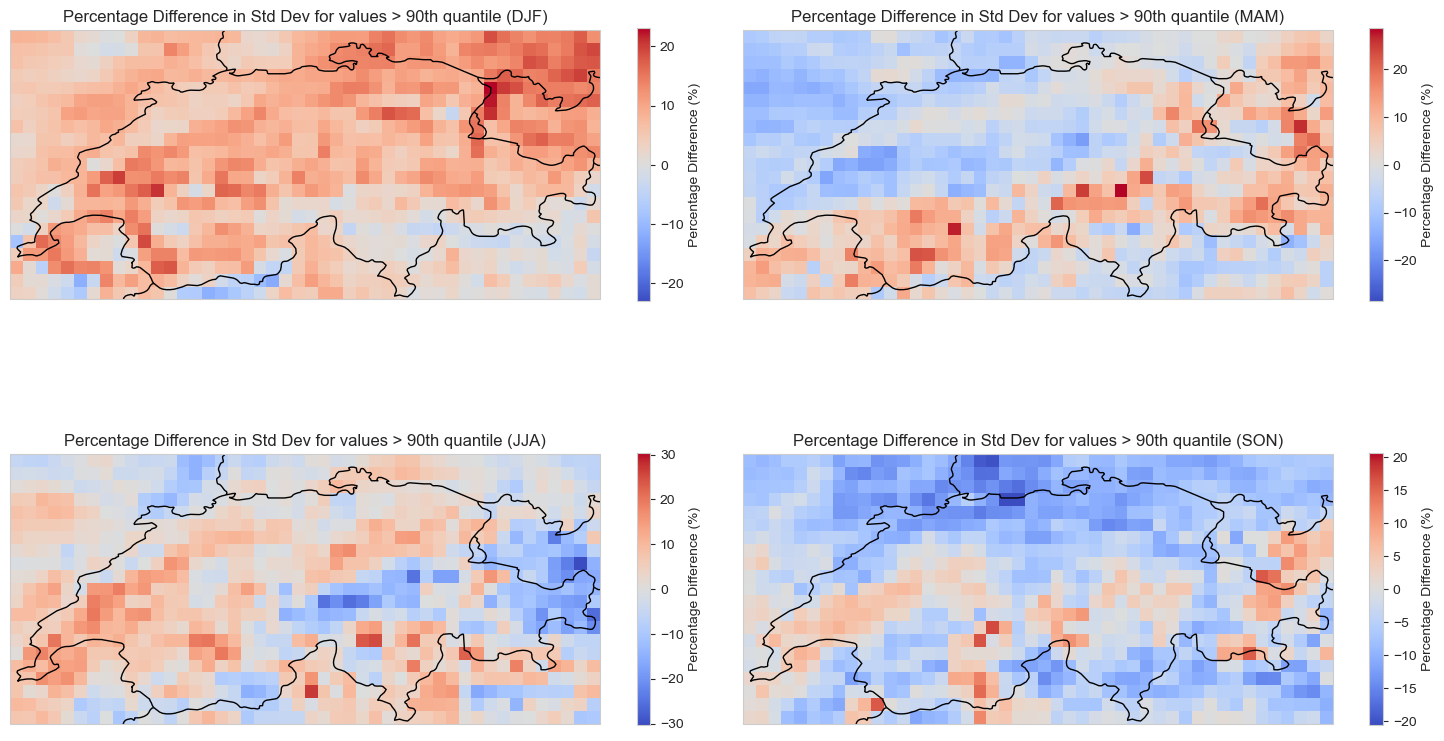

In [130]:
# Define the quantile threshold
quantile_threshold = 0.90

# # Group data by season and select values above the quantile threshold for each season
# above_quantile_reference_seasonal = (
#     ds_daily_sum[selected_var]
#     .sel(time=reference_period)
#     .groupby("time.season")
#     .apply(
#         lambda x: x.where(
#             x > x.quantile(quantile_threshold, dim="time")
#         )
#     )
# )

# above_quantile_future_seasonal = (
#     ds_daily_sum[selected_var]
#     .sel(time=future_period)
#     .groupby("time.season")
#     .apply(
#         lambda x: x.where(
#             x > x.quantile(quantile_threshold, dim="time")
#         )
#     )
# )

def compute_above_quantile_seasonal(ds, var, time_period, q):
    ds_period = ds[var].sel(time=time_period)
    results = []

    for season in ['DJF', 'MAM', 'JJA', 'SON']:
        ds_season = ds_period.sel(time=ds_period['time.season'] == season)

        # Quantile over time for each grid cell
        threshold = ds_season.quantile(q, dim='time')

        # Mask values above the threshold
        masked = ds_season.where(ds_season > threshold)

        # Add season as coordinate for stacking later
        masked = masked.expand_dims(season=[season])
        results.append(masked)

    return xr.concat(results, dim='season')

# Apply to reference and future
above_quantile_reference_seasonal = compute_above_quantile_seasonal(
    ds_daily_sum, selected_var, reference_period, quantile_threshold
)
above_quantile_future_seasonal = compute_above_quantile_seasonal(
    ds_daily_sum, selected_var, future_period, quantile_threshold
)

# Compute the standard deviation for each season
std_above_quantile_reference_seasonal = above_quantile_reference_seasonal.std(dim="time")
std_above_quantile_future_seasonal = above_quantile_future_seasonal.std(dim="time")

# Compute the percentage difference in standard deviation for each season
std_percentage_difference_seasonal = (
    (std_above_quantile_future_seasonal - std_above_quantile_reference_seasonal)
    / std_above_quantile_reference_seasonal
) * 100

# Plot the percentage difference for each season
fig, axes = plt.subplots(
    2, 2, figsize=(15, 10), subplot_kw={"projection": ccrs.PlateCarree()}
)
axes = axes.flatten()

for i, season in enumerate(std_percentage_difference_seasonal.season.values):
    ax = axes[i]
    std_percentage_difference_seasonal.sel(season=season).plot(
        ax=ax,
        cmap="coolwarm",
        cbar_kwargs={"label": "Percentage Difference (%)", "shrink": 0.5},
    )
    ax.set_title(f"Percentage Difference in Std Dev for values > 90th quantile ({season})")
    ax.add_feature(cfeature.BORDERS, linestyle="-", edgecolor="black")
    ax.add_feature(cfeature.COASTLINE, edgecolor="black")

plt.tight_layout()
plt.show()